In [1]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
import os
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import glob
%matplotlib inline
param_map = {
    '5ms': {'time': 5},
    '50ms': {'time': 0.5},
    '500ms': {'time': 0.1},
    '5gs': {'time': 0.01},
    '250ks': {'time': 20}
}

In [2]:
import os, re, csv
from typing import Optional, List, Dict, Any
from datetime import datetime, timezone
import numpy as np

# Accepts ..._<STAMP>... with STAMP = 20251124T192840Z or 20251124T192840+0000
STAMP_ANY = re.compile(r"_(\d{8}T\d{6}(?:Z|[+-]\d{4}))")

def _parse_stamp(s: str) -> Optional[datetime]:
    try:
        if s.endswith("Z"):
            return datetime.strptime(s, "%Y%m%dT%H%M%SZ").replace(tzinfo=timezone.utc)
        return datetime.strptime(s, "%Y%m%dT%H%M%S%z")
    except Exception:
        return None

def _load_meta(meta_path: str) -> Dict[str, str]:
    meta: Dict[str, str] = {}
    if not os.path.isfile(meta_path): return meta
    with open(meta_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or "=" not in line: continue
            k, v = line.split("=", 1)
            meta[k.strip()] = v.strip()
    return meta

def _load_from_npz(npz_path: str) -> Dict[str, Any]:
    out: Dict[str, Any] = {}
    with np.load(npz_path, allow_pickle=False) as z:
        for k in z.files:
            out[k] = z[k]
    return out

def _load_from_csv(csv_path: str) -> Dict[str, Any]:
    if not os.path.isfile(csv_path): return {}
    times, counts, voa, pm, reset = [], [], [], [], []
    with open(csv_path, "r", newline="", encoding="utf-8") as f:
        r = csv.reader(f)
        header = next(r, None)
        has_reset = False
        if header:
            hl = [h.strip().lower() for h in header]
            has_reset = ("reset_bin" in hl)
        for row in r:
            if not row: continue
            times.append(np.datetime64(row[0]))
            counts.append(int(float(row[1])))
            voa.append(float(row[2]))
            pm.append(float(row[3]))
            if has_reset and len(row) > 4:
                try: reset.append(bool(int(row[4])))
                except ValueError: reset.append(row[4].strip().lower() in ("true","t","yes","y"))
    data: Dict[str, Any] = {
        "timestamps": np.array(times, dtype="datetime64[us]"),
        "counts":     np.array(counts, dtype=np.uint32),
        "voa_volts":  np.array(voa, dtype=float),
        "pm_volts":   np.array(pm,  dtype=float),
    }
    if reset:
        data["reset_mask_bins"] = np.array(reset, dtype=bool)
    return data

def load_measurements(base_dir: str, date_str: str, subfolder: str, verbose: bool=False) -> List[Dict[str, Any]]:
    """
    Scans base_dir/YYYY-MM-DD/subfolder for triplets:
      <base>_<STAMP>*.npz
      <base>_<STAMP>*.csv
      <base>_<STAMP>*_meta.txt
    Uses the *last* stamp occurrence in the filename. Returns newest→oldest.
    """
    root = os.path.join(base_dir, date_str, subfolder)
    if not os.path.isdir(root):
        raise FileNotFoundError(f"Folder not found: {root}")

    recs: Dict[tuple, Dict[str, Any]] = {}
    for fn in os.listdir(root):
        full = os.path.join(root, fn)
        if not os.path.isfile(full): 
            if verbose: print("[skip dir]", fn)
            continue

        matches = list(STAMP_ANY.finditer(fn))
        if not matches:
            if verbose: print("[no stamp]", fn)
            continue
        m = matches[-1]                      # use the last stamp in the name
        stamp_str = m.group(1)
        stamp_dt  = _parse_stamp(stamp_str)
        if not stamp_dt:
            if verbose: print("[bad stamp]", fn, "|", stamp_str)
            continue

        base = fn[:m.start()]                # everything before the stamp
        kind = None
        if fn.endswith("_meta.txt"): kind = "meta"
        else:
            _, ext = os.path.splitext(fn)
            ext = ext.lower()
            if ext == ".npz": kind = "npz"
            elif ext == ".csv": kind = "csv"
        if not kind:
            if verbose: print("[unknown ext]", fn)
            continue

        key = (base, stamp_dt)
        rec = recs.setdefault(key, {"base": base.rstrip("_"), "stamp": stamp_dt, "npz": None, "csv": None, "meta": None})
        rec[kind] = full

    entries = sorted(recs.values(), key=lambda d: d["stamp"], reverse=True)

    out: List[Dict[str, Any]] = []
    for g in entries:
        data: Dict[str, Any] = {}
        meta: Dict[str, Any] = {}
        if g["npz"]:
            try: data = _load_from_npz(g["npz"])
            except Exception as e:
                if verbose: print("[npz load fail]", g["npz"], e)
        if not data and g["csv"]:
            try: data = _load_from_csv(g["csv"])
            except Exception as e:
                if verbose: print("[csv load fail]", g["csv"], e)
        if g["meta"]:
            try: meta = _load_meta(g["meta"])
            except Exception as e:
                if verbose: print("[meta load fail]", g["meta"], e)

        out.append({
            "name": g["base"],
            "timestamp": g["stamp"],   # tz-aware datetime
            "npz_path": g["npz"],
            "csv_path": g["csv"],
            "meta_path": g["meta"],
            "data": data,
            "meta": meta,
        })
    if verbose:
        print(f"Loaded {len(out)} measurements from {root}")
    return out


In [5]:
ms = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
ms2 = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
ms3 = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
ms4 = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long


In [7]:
NL = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [11]:
import numpy as np

def timestamps_to_elapsed_seconds(timestamps: np.ndarray) -> np.ndarray:
    """
    Convert an array of absolute timestamps (numpy datetime64)
    into time since start of measurement, in seconds.
    """
    ts = np.asarray(timestamps)

    if ts.dtype.kind != 'M':  # not a datetime64
        raise TypeError(f"Expected datetime64 array, got {ts.dtype}")

    # time offset from first sample
    dt = ts - ts[0]

    # convert timedeltas to float seconds
    elapsed_sec = dt / np.timedelta64(1, 's')
    return elapsed_sec.astype(float)


In [13]:
import numpy as np
from typing import Tuple, Dict, Any, List, Optional

# ----------------- helpers -----------------

def _timestr_to_seconds(tstr: str) -> float:
    h, m, s, us = tstr.split(':')
    return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

def _unwrap_seconds(sec: np.ndarray) -> np.ndarray:
    if sec.size <= 1:
        return sec.astype(float)
    out = sec.astype(float).copy()
    add = 0.0
    for i in range(1, sec.size):
        if sec[i] < sec[i-1]:
            add += 86400.0  # add a day after a rollover
        out[i] += add
    return out

def _visibility_from_block_sums(block_sums: np.ndarray) -> float:
    if block_sums.size == 0:
        return np.nan
    Nmin = float(np.min(block_sums))
    Nmax = float(np.max(block_sums))
    den = Nmax + Nmin
    return (Nmax - Nmin) / den if den > 0 else np.nan

# ------------- main function -------------

def point_binned_visibility(
    ts,
    counts,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    overlap: Optional[float] = None,   # <-- NEW: None or fraction in [0,1)
    verbose: bool = True
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, Dict[str, Any]]:
    """
    Point-binning visibility with analytic Poisson errors and optional window overlap.

    Parameters
    ----------
    overlap : None or float in [0,1)
        If None, use non-overlapping windows (stride = K).
        If given, use stride S = round(K*(1-overlap)).
        e.g., overlap=0.5 -> 50% overlap (S ≈ K/2).

    Returns
    -------
    taus, V, QBER, V_err, QBER_err, tau_err, diagnostics
    """
    # ---- prepare data
    ts = np.asarray(ts)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    secs = ts
    duration = float(secs[-1] - secs[0])
    
    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))
    dt_std  = float(np.std(dt_pos, ddof=1)) if dt_pos.size > 1 else 0.0
    dt_cv   = dt_std / dt_mean if dt_mean > 0 else np.nan

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per bin)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus = Ks * dt_mean
    V = np.empty_like(taus, dtype=float)
    QBER = np.empty_like(taus, dtype=float)
    V_err = np.full_like(taus, np.nan, dtype=float)
    QBER_err = np.full_like(taus, np.nan, dtype=float)
    tau_err = np.full_like(taus, np.nan, dtype=float)

    # Validate overlap
    if overlap is not None:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")

    # Diagnostics we’ll collect per K
    per_tau_diag: List[Dict[str, Any]] = []

    # ---- compute V(τ), analytic errors, and bin-size consistency
    for i, K in enumerate(Ks):
        # stride from overlap
        if overlap is None:
            stride = K
            overlap_eff = 0.0
        else:
            stride = max(1, int(round(K * (1.0 - overlap))))
            stride = min(stride, K)  # never exceed K
            overlap_eff = 1.0 - (stride / float(K))

        # starting indices; drop any final partial window (<K)
        if n < K:
            starts = np.array([], dtype=int)
        else:
            last_start = n - K
            starts = np.arange(0, last_start + 1, stride, dtype=int)

        n_blocks = int(starts.size)
        if n_blocks == 0:
            V[i] = np.nan
            QBER[i] = np.nan
            tau_err[i] = np.nan
            per_tau_diag.append({
                "K": int(K), "tau_target": K * dt_mean, "n_blocks": 0,
                "stride": int(stride), "overlap_eff": float(overlap_eff),
                "tau_mean": np.nan, "tau_std": np.nan, "rel_std": np.nan,
                "rmse_vs_target": np.nan, "max_abs_err": np.nan
            })
            continue

        # Efficient sliding sums via cumulative sum
        cs = np.concatenate(([0.0], np.cumsum(x, dtype=float)))
        ends = starts + K
        block_sums = cs[ends] - cs[starts]

        # Central V and QBER
        V[i] = _visibility_from_block_sums(block_sums)
        QBER[i] = 0.5 * (1.0 - np.abs(V[i])) if np.isfinite(V[i]) else np.nan

        # Analytic errors from A=Nmax, B=Nmin (Poisson)
        A = float(np.max(block_sums))
        B = float(np.min(block_sums))
        den = A + B
        if den > 0 and np.isfinite(V[i]):
            varV = 4.0 * A * B / (den ** 3)
            V_err[i] = np.sqrt(varV)
            QBER_err[i] = 0.5 * V_err[i]

        # Actual time-span of each window (first to last sample in window)
        durations = secs[ends - 1] - secs[starts]
        tau_target = K * dt_mean

        # Consistency metrics (and τ error)
        tau_mean = float(np.mean(durations)) if durations.size else np.nan
        tau_std  = float(np.std(durations, ddof=1)) if durations.size > 1 else 0.0
        tau_err[i] = tau_std
        rel_std  = (tau_std / tau_mean) if (durations.size and tau_mean > 0) else np.nan
        rmse     = float(np.sqrt(np.mean((durations - tau_target) ** 2))) if durations.size else np.nan
        max_err  = float(np.max(np.abs(durations - tau_target))) if durations.size else np.nan

        per_tau_diag.append({
            "K": int(K),
            "stride": int(stride),
            "overlap_eff": float(overlap_eff),   # actual overlap used
            "tau_target": tau_target,
            "n_blocks": n_blocks,
            "tau_mean": tau_mean,
            "tau_std": tau_std,
            "rel_std": rel_std,
            "rmse_vs_target": rmse,
            "max_abs_err": max_err,
        })

    diagnostics = {
        "sample_spacing": {
            "n_samples": int(n),
            "duration_s": duration,
            "dt_mean_s": dt_mean,
            "dt_std_s": dt_std,
            "dt_cv": dt_cv,
            "dt_min_s": float(np.min(dt_pos)),
            "dt_med_s": float(np.median(dt_pos)),
            "dt_max_s": float(np.max(dt_pos)),
            "pct_1_99_s": (float(np.percentile(dt_pos, 1)), float(np.percentile(dt_pos, 99)))
        },
        "per_tau": per_tau_diag
    }

    if verbose:
        ss = diagnostics["sample_spacing"]
        print("\n[Sample spacing diagnostics]")
        print(f"  n = {ss['n_samples']}, duration = {ss['duration_s']:.6f} s")
        print(f"  mean Δt = {ss['dt_mean_s']:.6e} s, std = {ss['dt_std_s']:.6e} s, CV = {ss['dt_cv']:.3g}")
        print(f"  min/median/max Δt = {ss['dt_min_s']:.6e} / {ss['dt_med_s']:.6e} / {ss['dt_max_s']:.6e} s")
        p1, p99 = ss["pct_1_99_s"]
        print(f"  1–99% Δt = {p1:.6e} … {p99:.6e} s")

        print("\n[Bin-size consistency per τ (point binning)]")
        print("  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)")
        for r in per_tau_diag:
            print(f"{r['K']:>3d}  {r['stride']:>6d}  {r['overlap_eff']:.2f}  {r['tau_target']:.6e}  "
                  f"{r['n_blocks']:>8d}  {r['tau_mean']:.6e}  {r['tau_std']:.6e}  "
                  f"{(r['rel_std'] if np.isfinite(r['rel_std']) else np.nan):>7.3g}  "
                  f"{r['rmse_vs_target']:.6e}  {r['max_abs_err']:.6e}")

    return taus, V, QBER, V_err, QBER_err, tau_err, diagnostics


In [15]:
import numpy as np

# ---------- time helpers ----------
def _timestr_to_seconds(tstr: str) -> float:
    h, m, s, us = tstr.split(':')
    return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

def _unwrap_seconds(sec: np.ndarray) -> np.ndarray:
    if sec.size <= 1:
        return sec.astype(float)
    out = sec.astype(float).copy()
    add = 0.0
    for i in range(1, sec.size):
        if sec[i] < sec[i-1]:
            add += 86400.0  # day rollover
        out[i] += add
    return out

def _seconds_to_timestr(t: float) -> str:
    # format seconds (can exceed 24h); we fold modulo 86400 for the string
    t_mod = t % 86400.0
    h = int(t_mod // 3600)
    m = int((t_mod % 3600) // 60)
    s = int(t_mod % 60)
    us = int(round((t_mod - int(t_mod)) * 1e6))
    # handle rounding to next second
    if us == 1_000_000:
        us = 0; s += 1
        if s == 60:
            s = 0; m += 1
            if m == 60:
                m = 0; h = (h + 1) % 24
    return f"{h:02d}:{m:02d}:{s:02d}:{us:06d}"

# ---------- main ----------
def bin_by_tau_point(
    ts,
    counts,
    tau: float,
    ts_mode: str = "start",          # 'start' | 'end' | 'center'
    include_partial: str = "drop"    # 'drop' | 'keep' | 'normalize'
):
    """
    Bin by a single τ using point-binning (K samples per bin, K ≈ tau / mean Δt).

    Parameters
    ----------
    ts : array-like of str ('HH:MM:SS:ffffff')
    counts : array-like of non-negative numbers
    tau : float, target bin size in seconds
    ts_mode : which timestamp to emit per bin:
        'start' -> first sample's original timestamp (default)
        'end'   -> last sample's original timestamp
        'center'-> mean time of samples in the bin (formatted back to string)
    include_partial : how to treat the final short bin (<K samples):
        'drop'      -> drop it (same as earlier code) [default]
        'keep'      -> keep raw sum (short bin often becomes Nmin)
        'normalize' -> scale the short-bin sum by K/L to be comparable to full bins

    Returns
    -------
    ts_binned : np.ndarray of str, one timestamp per bin
    counts_binned : np.ndarray of float, sum per bin (normalized if requested)
    info : dict with metadata (K, tau_effective, n_bins, dropped_samples, etc.)
    """
    ts = np.asarray(ts)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 1:
        return np.array([], dtype=str), np.array([], dtype=float), {
            "K": 0, "tau_effective": np.nan, "n_bins": 0, "dropped_samples": 0
        }

    # Parse / unwrap time, compute mean Δt and K from tau
    secs = ts
    if n < 2:
        # only one point -> one-bin result if include_partial!='drop'
        if include_partial == "drop":
            return np.array([], dtype=str), np.array([], dtype=float), {
                "K": 1, "tau_effective": np.nan, "n_bins": 0, "dropped_samples": 1
            }
        # keep/normalize: single bin with that point
        ts_b = np.array([ts[0]])
        cnts = np.array([x[0]], dtype=float)
        return ts_b, cnts, {"K": 1, "tau_effective": 0.0, "n_bins": 1, "dropped_samples": 0}

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))

    K = max(1, int(np.rint(float(tau) / dt_mean)))
    tau_eff = K * dt_mean

    # Build bins of K samples
    if include_partial == "drop":
        n_full = (n // K) * K
        starts = np.arange(0, n_full, K, dtype=int)
        lens = np.full_like(starts, K)
        dropped = n - n_full
    else:
        n_bins = int(np.ceil(n / K))
        starts = np.arange(0, n_bins * K, K, dtype=int)
        lens = np.minimum(K, n - starts)
        lens = lens[lens > 0]
        starts = starts[:lens.size]
        dropped = 0

    # Sums per bin
    sums = np.add.reduceat(x, starts)
    sums = sums[:lens.size]  # guard
    if include_partial == "normalize":
        # scale short bins to K-sample equivalent
        scale = (K / lens.astype(float))
        sums = sums * scale

    # Timestamp per bin
    if ts_mode == "start":
        ts_binned = ts[starts]
    elif ts_mode == "end":
        ts_binned = ts[starts + lens - 1]
    elif ts_mode == "center":
        centers = []
        for s0, L in zip(starts, lens):
            t_mean = float(np.mean(secs[s0:s0+L]))
        ts_binned = np.array(t_mean, dtype=object)
    else:
        raise ValueError("ts_mode must be one of {'start','end','center'}")

    info = {
        "K": int(K),
        "tau_effective": float(tau_eff),
        "requested_tau": float(tau),
        "n_bins": int(len(sums)),
        "dropped_samples": int(dropped),
        "include_partial": include_partial,
        "ts_mode": ts_mode,
    }
    return ts_binned, sums.astype(float), info


In [17]:
import numpy as np
from typing import Optional, Tuple

def rolling_visibility_segments(
    ts: np.ndarray,
    counts: np.ndarray,
    phase_length: float,
    overlap: Optional[float] = None,
    min_points: int = 2,   # require at least this many samples per segment
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Slide a window of length `phase_length` (s) across the data (optionally overlapped),
    and compute per-segment visibility and its analytic 1σ error assuming Poisson counts.

    Visibility in a segment:
        A = max(counts in segment)
        B = min(counts in segment)
        V = (A - B) / (A + B)
        σ_V = sqrt( 4 A B / (A + B)^3 )

    Parameters
    ----------
    ts : array-like of float
        Timestamps in seconds (nondecreasing).
    counts : array-like of float
        Non-negative counts per sample (same length/order as ts).
    phase_length : float
        Segment duration (seconds), must be > 0.
    overlap : None or float in [0,1)
        If None: non-overlapping segments (stride = phase_length).
        Else: stride = phase_length * (1 - overlap). Example: 0.5 -> 50% overlap.
    min_points : int
        Minimum number of samples required in a segment to compute visibility.

    Returns
    -------
    t_centers : np.ndarray (float)
        Center time of each segment (start + phase_length/2).
    V : np.ndarray (float)
        Visibility per segment (NaN when undefined).
    V_err : np.ndarray (float)
        Analytic 1σ error per segment (NaN when undefined).
    """
    ts = np.asarray(ts, dtype=float)
    x  = np.asarray(counts, dtype=float)

    if ts.size != x.size:
        raise ValueError("ts and counts must have the same length.")
    if ts.size == 0:
        return np.array([], float), np.array([], float), np.array([], float)
    if phase_length <= 0:
        raise ValueError("phase_length must be > 0.")

    # stride from overlap
    if overlap is None:
        stride = phase_length
    else:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")
        stride = phase_length * (1.0 - overlap)
        if stride <= 0:
            stride = np.finfo(float).eps  # guard

    # sanitize counts (non-negative, finite)
    x = np.clip(np.nan_to_num(x, nan=0.0), 0.0, None)

    t0, t1 = ts[0], ts[-1]
    if (t1 - t0) < phase_length:
        return np.array([], float), np.array([], float), np.array([], float)

    # build segment starts and centers
    n_segs = int(np.floor((t1 - t0 - phase_length) / stride)) + 1
    starts  = t0 + np.arange(n_segs, dtype=float) * stride
    centers = starts + 0.5 * phase_length

    V     = np.full(n_segs, np.nan, dtype=float)
    V_err = np.full(n_segs, np.nan, dtype=float)

    # two-pointer sweep
    i_start = 0
    i_end   = 0
    N = ts.size

    for k, s in enumerate(starts):
        seg_end = s + phase_length
        # advance to segment bounds
        while i_start < N and ts[i_start] < s:
            i_start += 1
        if i_end < i_start:
            i_end = i_start
        while i_end < N and ts[i_end] < seg_end:
            i_end += 1

        L = i_end - i_start
        if L >= min_points:
            seg_vals = x[i_start:i_end]
            A = float(np.max(seg_vals))
            B = float(np.min(seg_vals))
            den = A + B
            if den > 0:
                V[k] = (A - B) / den
                # analytic 1σ (delta-method, treating A,B independent Poisson)
                V_err[k] = np.sqrt(4.0 * A * B / (den ** 3))
            else:
                V[k] = np.nan
                V_err[k] = np.nan
        else:
            V[k] = np.nan
            V_err[k] = np.nan

    return centers, V, V_err


In [19]:
import numpy as np
from typing import Any, Dict, List, Optional, Tuple

def point_binned_visibility_over_timeframes(
    ts,
    counts,
    frame_duration_s: float,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    overlap: Optional[float] = None,   # overlap between τ-windows (not frames)
    verbose: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    For each τ, partition the data into time frames of approximately `frame_duration_s`
    and compute a visibility V for each frame. Then return, for each τ, the maximum
    visibility and minimum visibility across all frames.

    Parameters
    ----------
    ts : array_like
        Timestamps in seconds (monotonic, not necessarily uniform).
    counts : array_like
        Counts associated with each timestamp.
    frame_duration_s : float
        Length of each analysis frame in seconds. The data are partitioned into
        consecutive, non-overlapping frames of this duration (approx, based on mean dt).
        If the total duration is shorter than frame_duration_s, a single frame
        spanning the whole dataset is used.
    n_taus : int, optional
        Number of τ values (K-values) to evaluate.
    tau_max : float or None, optional
        Maximum τ in seconds; if None, defaults to half the total duration.
    log_bins : bool, optional
        If True, choose K (and thus τ) on a log scale; otherwise linear.
    overlap : None or float in [0,1), optional
        Overlap fraction for τ-windows inside each frame.
        - None  -> non-overlapping τ-windows (stride = K)
        - value -> stride = round(K * (1 - overlap))
    verbose : bool, optional
        If True, print some diagnostics.

    Returns
    -------
    taus : np.ndarray, shape (M,)
        τ values in seconds (one per K).
    maxvis : np.ndarray, shape (M,)
        For each τ, the maximum visibility over all frames (NaN if no frames valid).
    minvis : np.ndarray, shape (M,)
        For each τ, the minimum visibility over all frames (NaN if no frames valid).
    """
    # ---- prepare data
    ts = np.asarray(ts)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    secs = ts
    duration = float(secs[-1] - secs[0])

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per τ window)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus = Ks * dt_mean

    # ---- validate overlap
    if overlap is not None:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")

    # ---- define time frames in samples
    if frame_duration_s <= 0:
        raise ValueError("frame_duration_s must be > 0.")

    # Number of samples per frame, based on mean dt
    frame_K = max(1, int(round(frame_duration_s / dt_mean)))

    if duration <= frame_duration_s:
        # Single frame spanning the whole dataset
        frame_starts = np.array([0], dtype=int)
        frame_ends   = np.array([n], dtype=int)
    else:
        # Multiple non-overlapping frames of approx frame_duration_s
        last_start = n - frame_K
        if last_start < 0:
            # Not enough samples; just one frame using all data
            frame_starts = np.array([0], dtype=int)
            frame_ends   = np.array([n], dtype=int)
        else:
            frame_starts = np.arange(0, last_start + 1, frame_K, dtype=int)
            frame_ends   = frame_starts + frame_K
            # If the last frame end would exceed n, clip or drop:
            frame_ends = np.minimum(frame_ends, n)

    n_frames = frame_starts.size
    if verbose:
        print(f"[Frames] Using {n_frames} frame(s) with nominal duration "
              f"{frame_duration_s:.3f} s (≈ {frame_K} samples per frame).")

    # ---- output arrays
    maxvis = np.full_like(taus, np.nan, dtype=float)
    minvis = np.full_like(taus, np.nan, dtype=float)

    # ---- main loop over τ (over K)
    for i, K in enumerate(Ks):
        # stride for τ-windows
        if overlap is None:
            stride = K
        else:
            stride = max(1, int(round(K * (1.0 - overlap))))
            stride = min(stride, K)

        vis_per_frame: List[float] = []

        for f in range(n_frames):
            fs = frame_starts[f]
            fe = frame_ends[f]

            # Segment data for this frame
            seg_x = x[fs:fe]
            seg_n = seg_x.size

            if seg_n < K:
                # Not enough samples in frame for this τ
                continue

            # Sliding sums within this frame
            last_start_local = seg_n - K
            starts_local = np.arange(0, last_start_local + 1, stride, dtype=int)
            if starts_local.size == 0:
                continue

            cs_local = np.concatenate(([0.0], np.cumsum(seg_x, dtype=float)))
            ends_local = starts_local + K
            block_sums = cs_local[ends_local] - cs_local[starts_local]

            # Visibility for this τ and this frame
            V_frame = _visibility_from_block_sums(block_sums)
            if np.isfinite(V_frame):
                vis_per_frame.append(float(V_frame))

        if vis_per_frame:
            vis_arr = np.asarray(vis_per_frame, dtype=float)
            maxvis[i] = np.max(vis_arr)
            minvis[i] = np.min(vis_arr)
        else:
            maxvis[i] = np.nan
            minvis[i] = np.nan

        if verbose:
            print(f"τ[{i}] = {taus[i]:.3e} s (K={K:>4d}) -> frames used: "
                  f"{len(vis_per_frame):>3d}, "
                  f"maxV={maxvis[i]: .4f}, minV={minvis[i]: .4f}")

    return taus, maxvis, minvis


In [21]:
import numpy as np

def timestamps_to_elapsed_seconds(timestamps: np.ndarray) -> np.ndarray:
    """
    Convert an array of absolute timestamps (numpy datetime64)
    into time since start of measurement, in seconds.
    """
    ts = np.asarray(timestamps)

    if ts.dtype.kind != 'M':  # not a datetime64
        raise TypeError(f"Expected datetime64 array, got {ts.dtype}")

    # time offset from first sample
    dt = ts - ts[0]

    # convert timedeltas to float seconds
    elapsed_sec = dt / np.timedelta64(1, 's')
    return elapsed_sec.astype(float)
def AnalyseMeasurement(ms,i,n_taus,tau,phase_length,firsthalf=True,secondhalf=True):
    ts=timestamps_to_elapsed_seconds(ms[i]['data']['timestamps'])
    cts=ms[i]['data']['counts']
    taus, Vmax, Vmin = point_binned_visibility_over_timeframes(ts, cts, frame_duration_s=phase_length , n_taus=n_taus ,tau_max=1, log_bins=True,overlap=0.5, verbose=False)
    if firsthalf==True:
        fig1,axes1 = plt.subplots(ncols=2,figsize=(14, 3))
        axes1[0].semilogx(taus,Vmax,label='Vmax')
        axes1[0].semilogx(taus,Vmin,label='Vmin')
        axes1[0].set_title('Plot of Max Visibility/QBER vs Tau')
        axes1[0].axvline(tau, color='gray', linestyle='--')
        axes1[0].legend()
        axes1[0].set_ylim(0,1.05)
    ts_b, counts_b, meta = bin_by_tau_point(ts, cts, tau, ts_mode="start", include_partial="normalize")
    if firsthalf==True:
        axes1[1].plot(ts_b,counts_b,color='tab:orange')
        axes1[1].set_title('Plot of Counts vs Time, binned at Tau')
        axes1[1].set_ylim(0,np.max(counts_b))
    tsrv, Vrv, Vrver=rolling_visibility_segments(ts_b, counts_b,phase_length=phase_length, overlap=None)
    QBERrv=(1-Vrv)/2
    QBERrver=0.5*Vrver
    if secondhalf==True:
        fig2,axes2 = plt.subplots(ncols=2,figsize=(14, 3))
        axes2[0].scatter(tsrv,Vrv,color='tab:blue')
        axes2[0].errorbar(tsrv,Vrv,yerr=Vrver,color='tab:green', alpha=0.1)
        axes2[0].set_title('Plot of Visibility vs Time, binned at Tau')
        axes2[0].set_ylim(0.2,1.05)
        axes2[1].errorbar(tsrv,QBERrv,yerr=QBERrver,color='red', alpha=0.1)
        axes2[1].scatter(tsrv,QBERrv,color='tab:green')
        axes2[1].set_title('Plot of QBER vs Time, binned at Tau')
        axes2[1].set_ylim(0,0.5)
    pb_vis=[taus, Vmax, Vmin]
    bn_b_tau=[ts_b, counts_b, meta]
    roll_vis=[tsrv, Vrv, Vrver,QBERrv,QBERrver]
    values=[pb_vis,bn_b_tau,roll_vis]
    return(values)


In [57]:
for i in range(len(ms)):
    print(i,ms[i]['name'])

0 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_195uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_195uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_195uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_195uWperArm_Rmp100Hz
10 Night_2_1MhzGate_195uWperArm_Rmp10Hz
11 Night_2_1MhzGate_195uWperArm_Rmp1Hz
12 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
13 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation


In [93]:
for i in range(len(ms2)):
    print(i,ms2[i]['name'])

0 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_153uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_153uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_153uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_153uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_153uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_153uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_153uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_153uWperArm_Rmp100Hz
10 Night_2_1MhzGate_153uWperArm_Rmp10Hz
11 Night_2_1MhzGate_153uWperArm_Rmp1Hz


In [95]:
for i in range(len(ms3)):
    print(i,ms3[i]['name'])

0 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz_voaramp
1 Medium_2_1MhzGate_130uWperArm_Rmp100Hz_voaramp
2 Medium_2_1MhzGate_130uWperArm_Rmp10Hz_voaramp
3 Medium_2_1MhzGate_130uWperArm_Rmp1Hz_voaramp
4 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz_nomodulation
5 Medium_2_1MhzGate_130uWperArm_Rmp100Hz_nomodulation
6 Medium_2_1MhzGate_130uWperArm_Rmp10Hz_nomodulation
7 Medium_2_1MhzGate_130uWperArm_Rmp1Hz_nomodulation
8 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz
9 Medium_2_1MhzGate_130uWperArm_Rmp100Hz
10 Medium_2_1MhzGate_130uWperArm_Rmp10Hz
11 Medium_2_1MhzGate_130uWperArm_Rmp1Hz
12 Medium_2_1MhzGate_167uWperArm_Rmp1000Hz_voaramp


In [97]:
for i in range(len(ms4)):
    print(i,ms4[i]['name'])

0 Day_2_1MhzGate_85uWperArm_Rmp1Hz
1 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_voaramp
2 Day_2_1MhzGate_85uWperArm_Rmp100Hz_voaramp
3 Day_2_1MhzGate_85uWperArm_Rmp10Hz_voaramp
4 Day_2_1MhzGate_85uWperArm_Rmp1Hz_voaramp
5 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_nomodulation
6 Day_2_1MhzGate_85uWperArm_Rmp100Hz_nomodulation
7 Day_2_1MhzGate_85uWperArm_Rmp10Hz_nomodulation
8 Day_2_1MhzGate_85uWperArm_Rmp1Hz_nomodulation
9 Day_2_1MhzGate_85uWperArm_Rmp1000Hz
10 Day_2_1MhzGate_85uWperArm_Rmp100Hz
11 Day_2_1MhzGate_85uWperArm_Rmp10Hz
12 Day_2_1MhzGate_85uWperArm_Rmp1Hz


In [47]:
ms[3]['name']

'Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp'

In [107]:
for i in range(len(NL)):
    print(i,NL[i]['name'])

0 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_158uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_158uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_158uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_158uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_158uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_158uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_158uWperArm_Rmp100Hz
10 Night_2_1MhzGate_158uWperArm_Rmp10Hz
11 Night_2_1MhzGate_158uWperArm_Rmp1Hz
12 Night_2_1MhzGate_158uWperArm_Rmp1Hz


In [109]:
for i in range(len(NLF)):
    print(i,NLF[i]['name'])

0 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_voaramp
1 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_voaramp
2 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_voaramp
3 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_voaramp
4 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_nomodulation
5 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_nomodulation
6 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_nomodulation
7 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_nomodulation
8 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz
9 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz
10 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz
11 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz
12 NightFast_2_1MhzGate_158uWperArm_Rmp1Hz


In [111]:
for i in range(len(NLVF)):
    print(i,NLVF[i]['name'])

0 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_voaramp
1 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_voaramp
2 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_voaramp
3 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_voaramp
4 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_nomodulation
5 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_nomodulation
6 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_nomodulation
7 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_nomodulation
8 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz
9 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz
10 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz
11 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz
12 NightVeryFast_2_1MhzGate_145uWperArm_Rmp1Hz


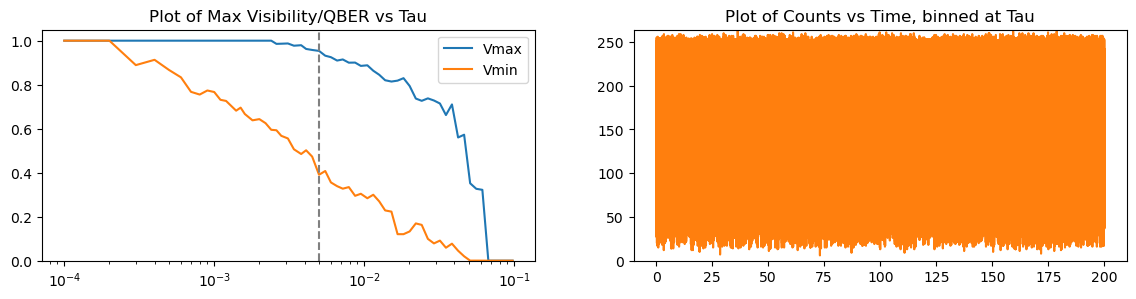

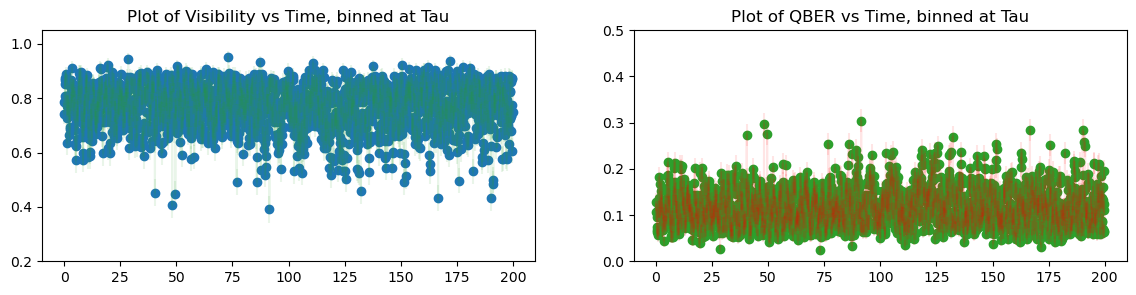

In [125]:
values10noM=AnalyseMeasurement(ms,8,100,0.005,0.1,secondhalf=True)

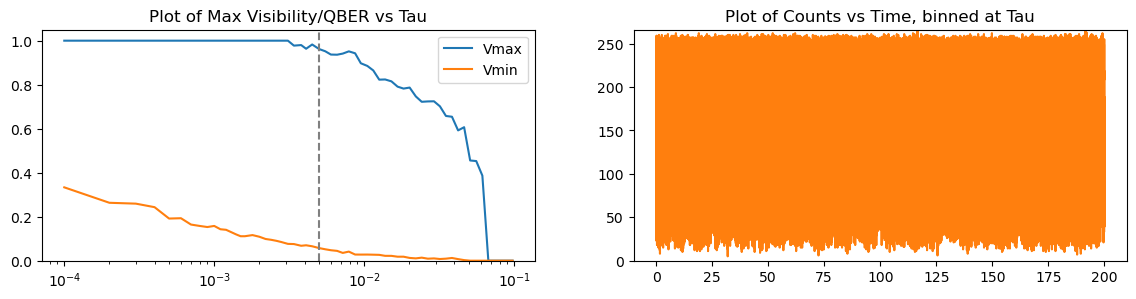

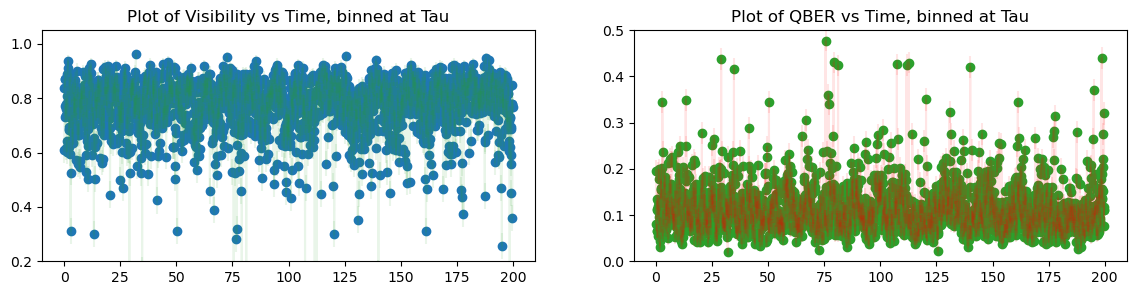

In [126]:
values10noM=AnalyseMeasurement(NLF,10,100,0.005,0.1,secondhalf=True)

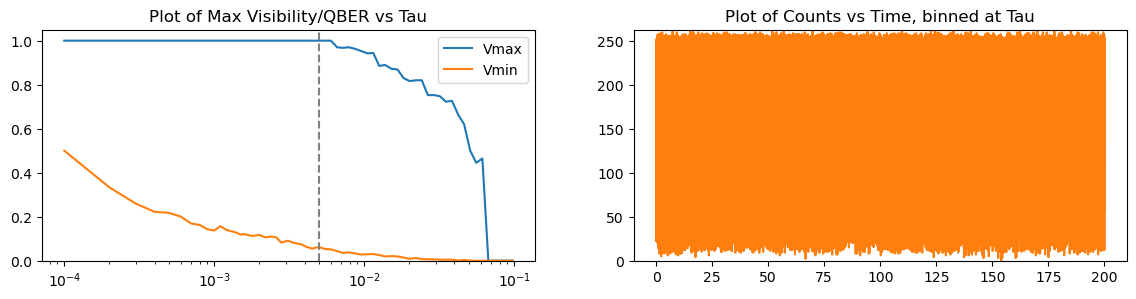

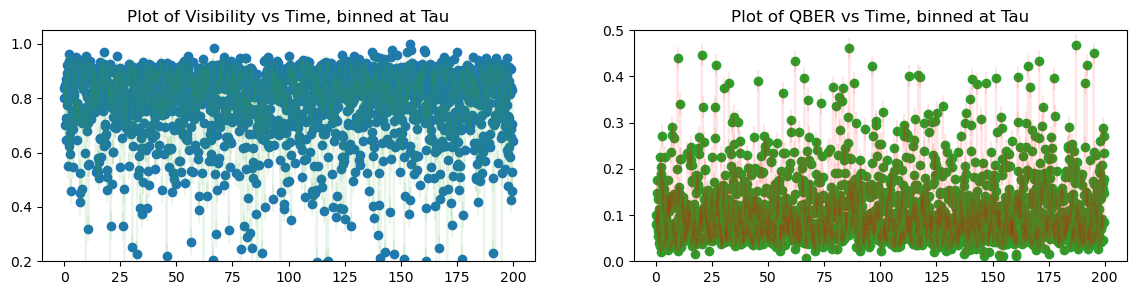

In [127]:
values10noM=AnalyseMeasurement(NLVF,10,100,0.005,0.1,secondhalf=True)

In [49]:
%matplotlib inline

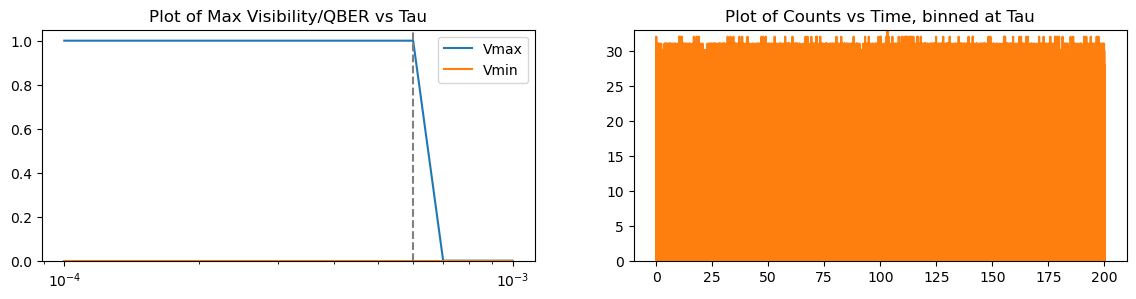

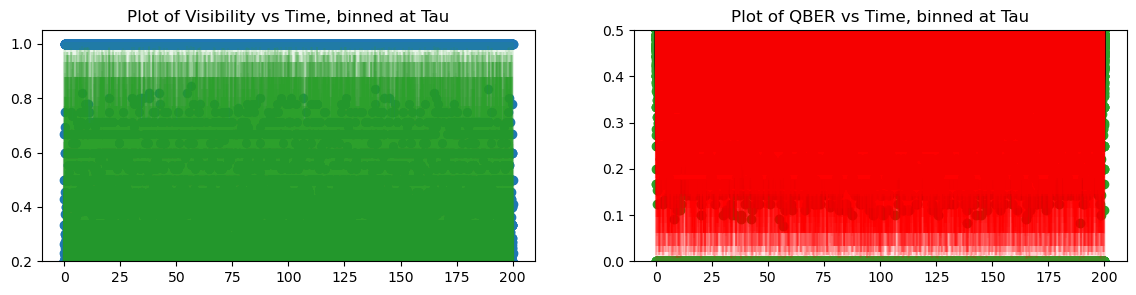

In [85]:
values10noM=AnalyseMeasurement(ms,10,100,0.0006,0.001,secondhalf=True)

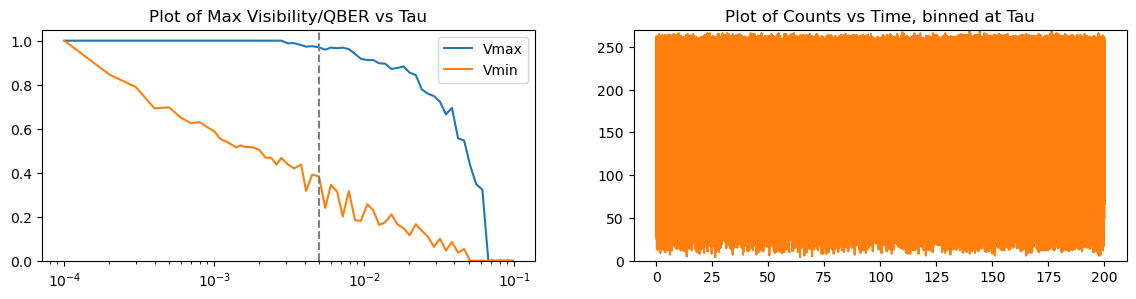

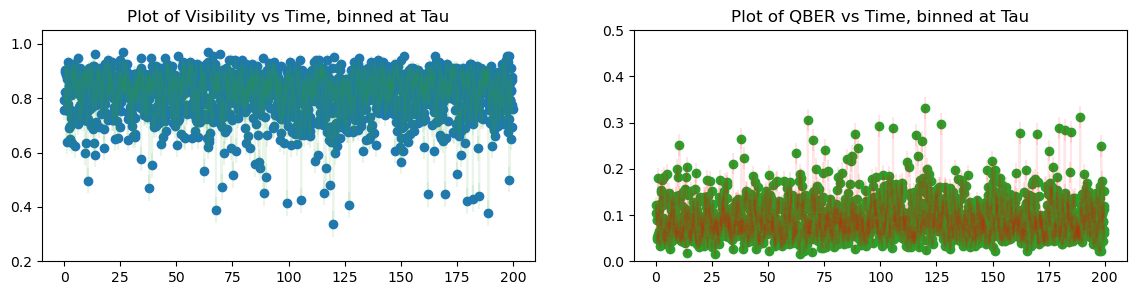

In [70]:
values10noM=AnalyseMeasurement(ms2,10,100,0.005,0.10,secondhalf=True)

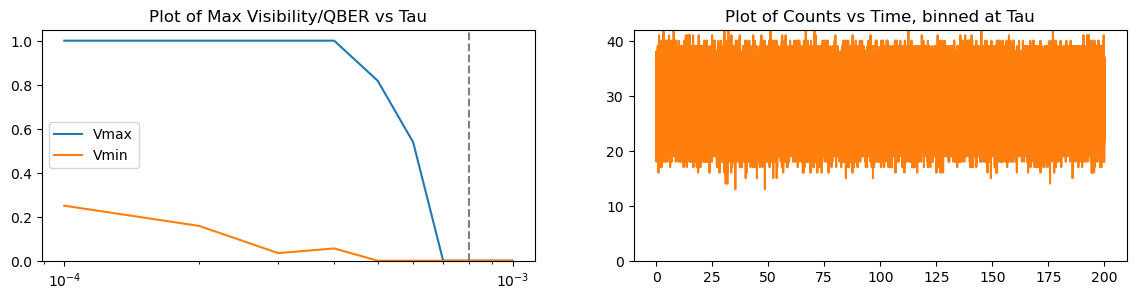

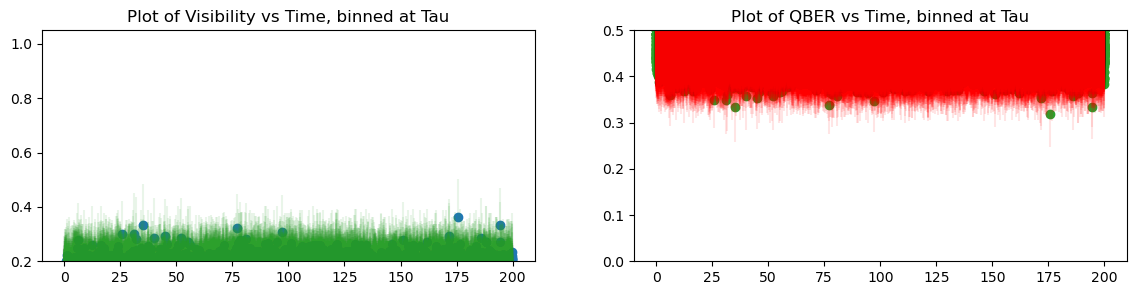

In [76]:
values10noM=AnalyseMeasurement(ms2,8,100,0.0008,0.001,secondhalf=True)

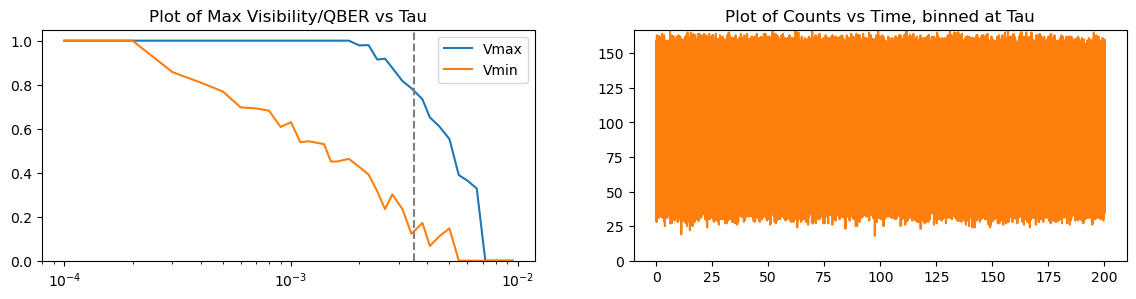

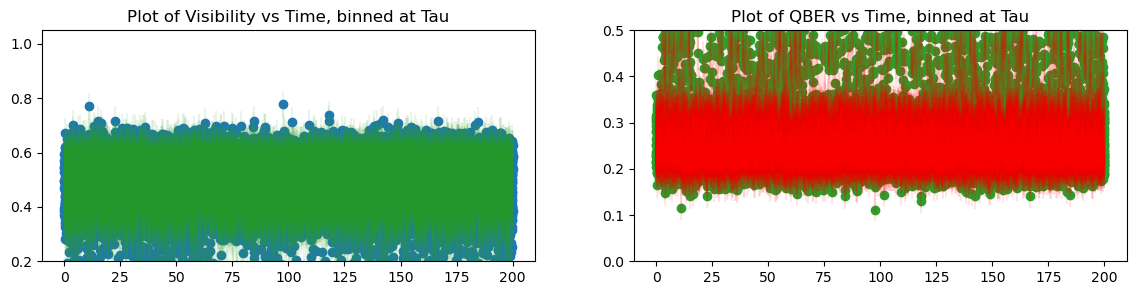

In [77]:
values10noM=AnalyseMeasurement(ms,9,100,0.0035,0.01,secondhalf=True)

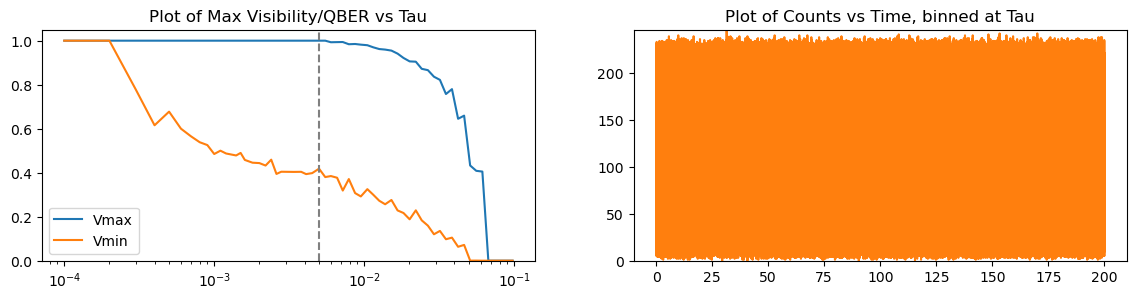

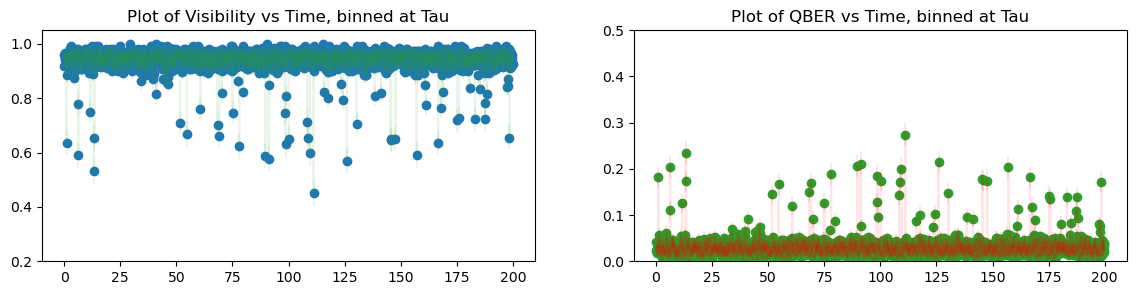

In [81]:
values10noM=AnalyseMeasurement(ms,10,100,0.005,0.10,secondhalf=True)

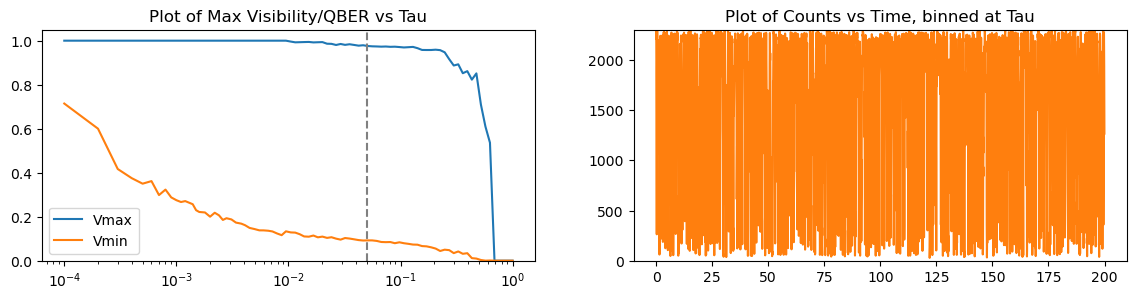

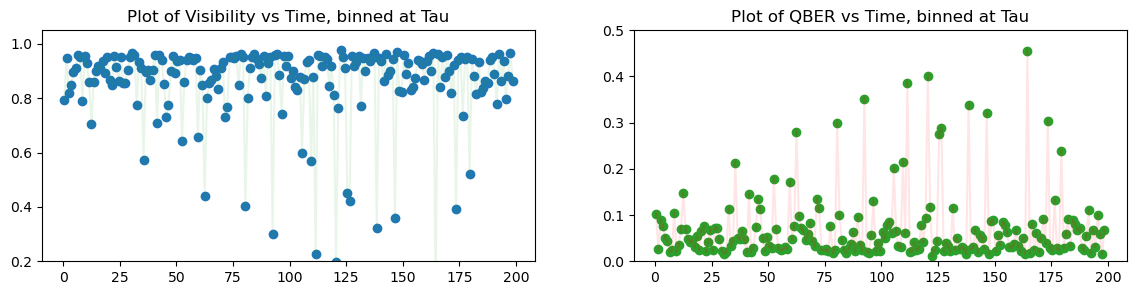

In [82]:
values10noM=AnalyseMeasurement(ms,11,100,0.05,1,secondhalf=True)

In [ ]:
values10noM=AnalyseMeasurement(ms2,10,100,0.0006,0.001,secondhalf=True)

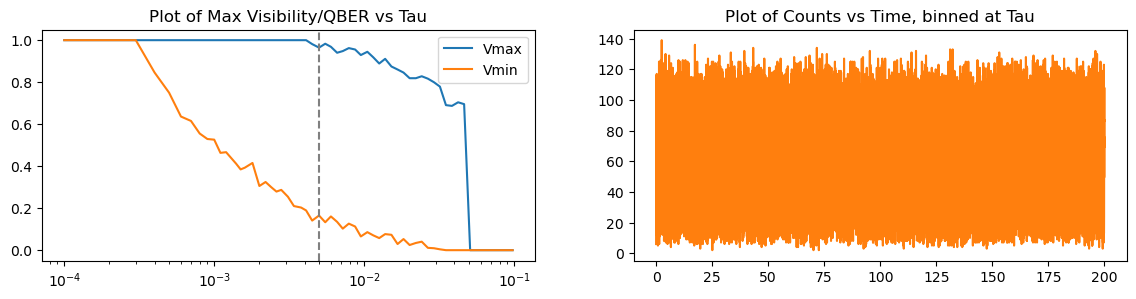

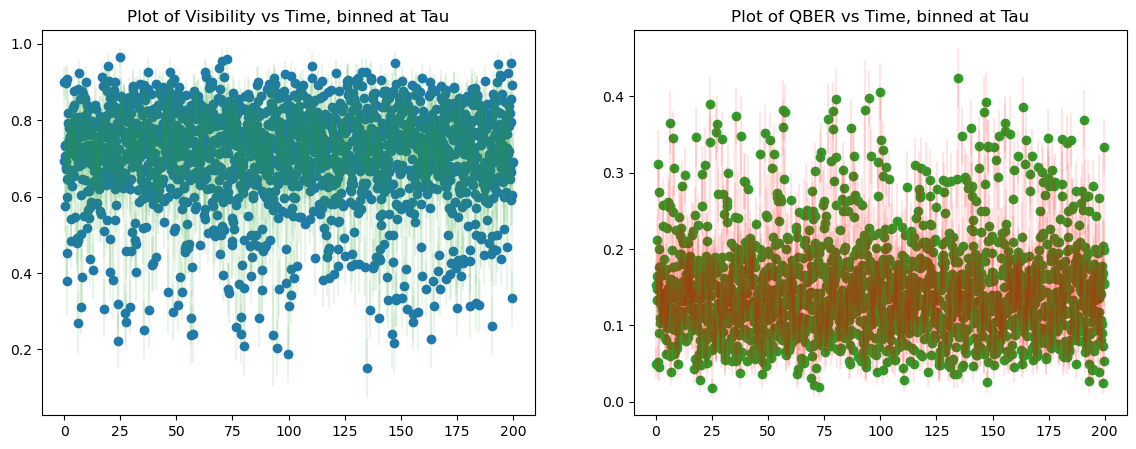

In [532]:
values10Emu=AnalyseMeasurement(ms,7,100,0.005,0.10,secondhalf=True)

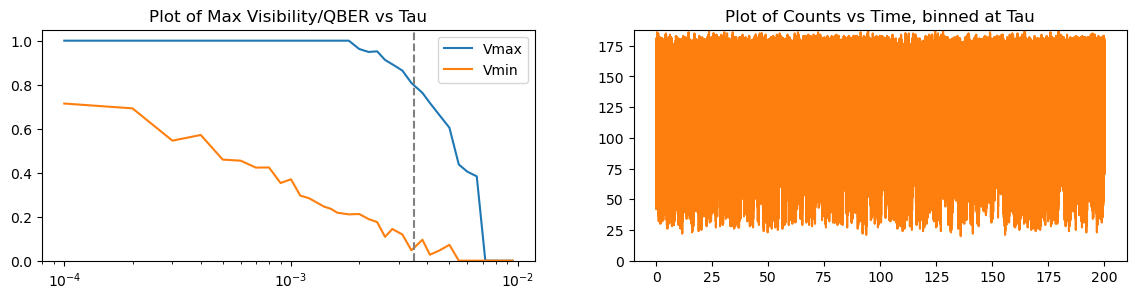

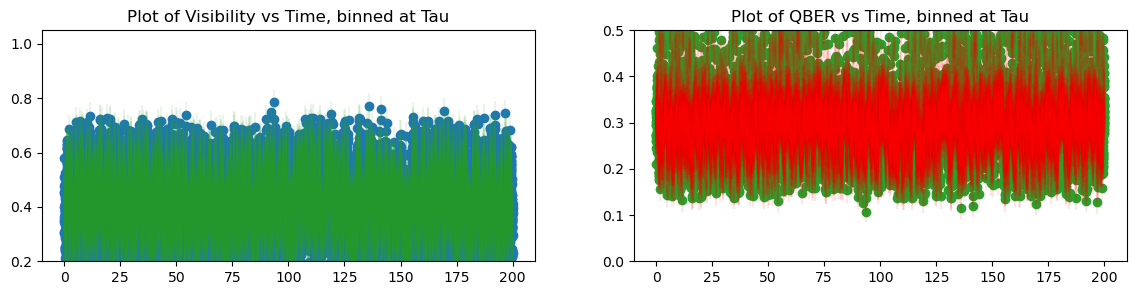

In [99]:
values10noM=AnalyseMeasurement(ms2,9,100,0.0035,0.01,secondhalf=True)

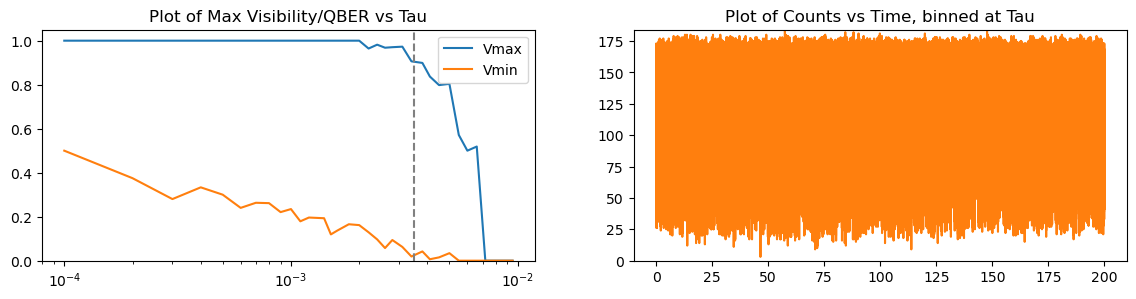

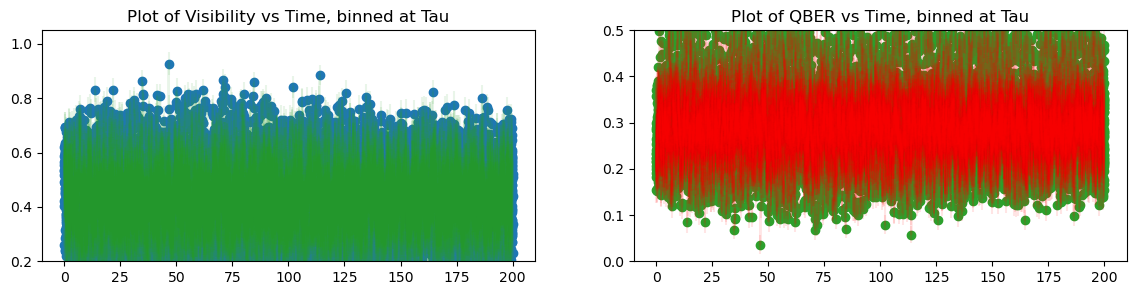

In [100]:
values10noM=AnalyseMeasurement(ms3,9,100,0.0035,0.01,secondhalf=True)

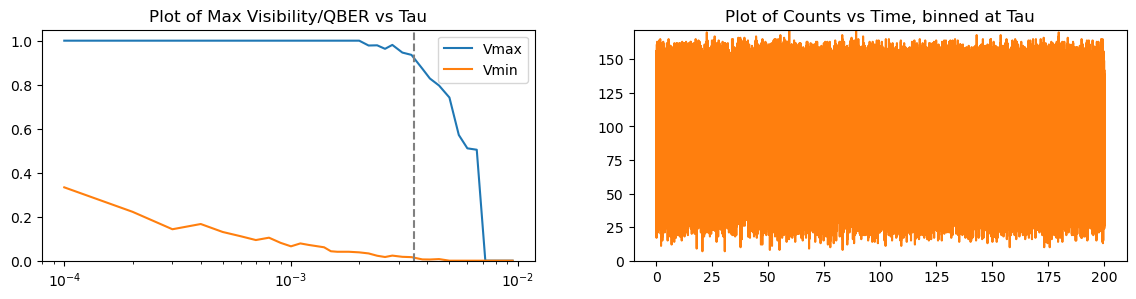

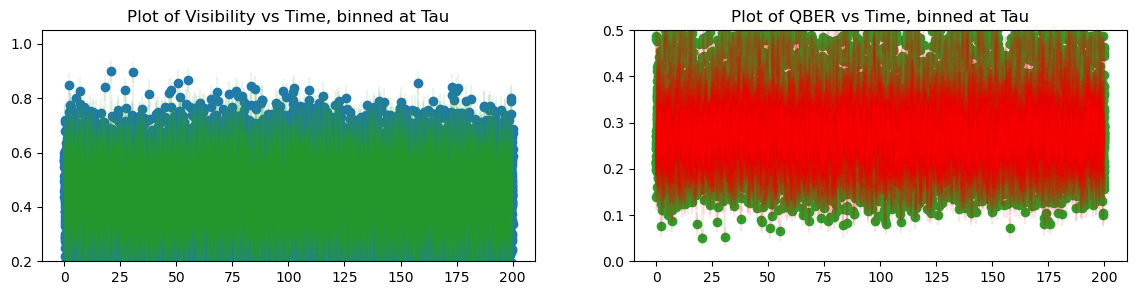

In [102]:
values10noM=AnalyseMeasurement(ms4,10,100,0.0035,0.01,secondhalf=True)

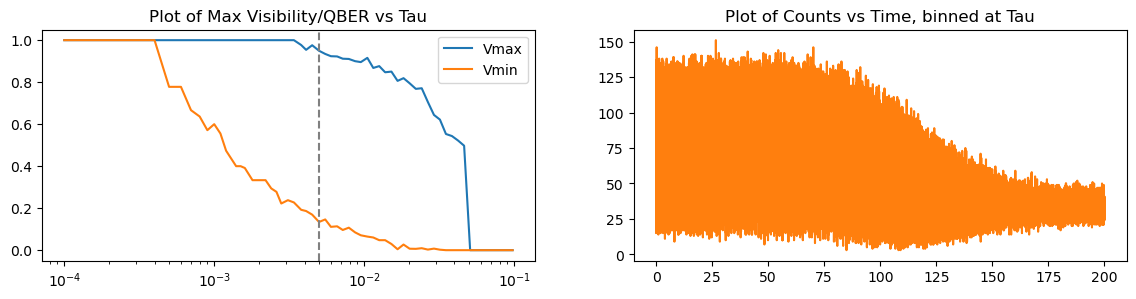

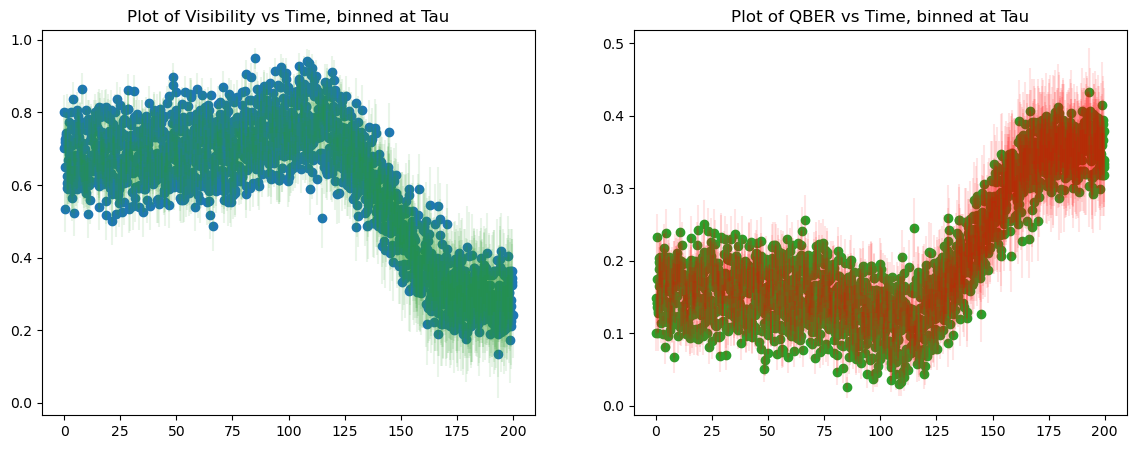

In [533]:
values10VoaRmp=AnalyseMeasurement(ms,1,100,0.005,0.10,secondhalf=True)

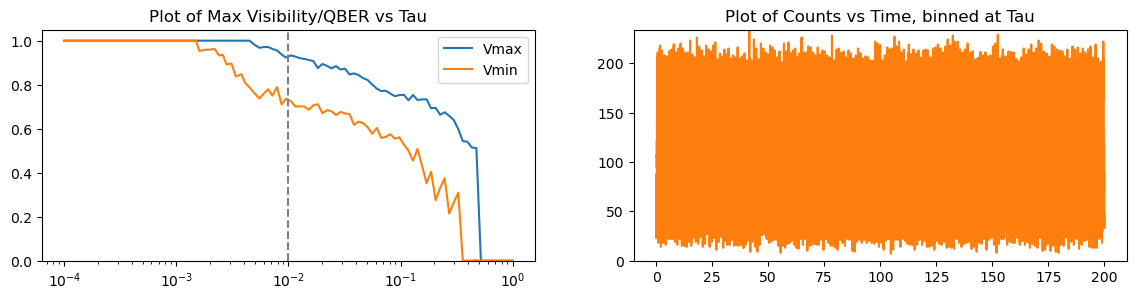

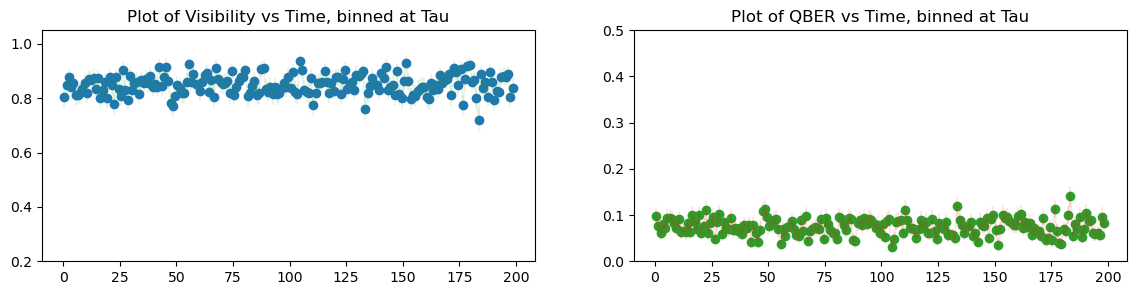

In [575]:
values1noM=AnalyseMeasurement(ms,4,100,0.01,1,secondhalf=True)

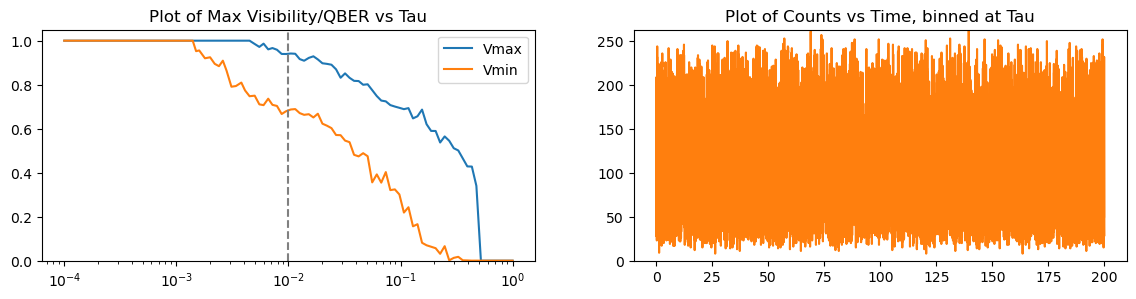

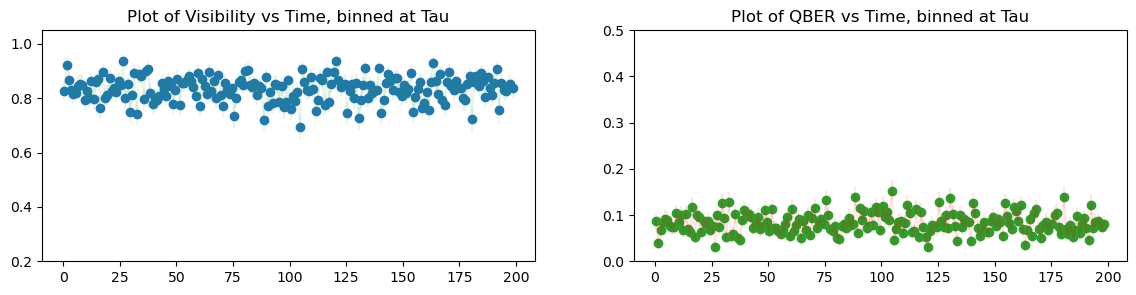

In [576]:
values1Emu=AnalyseMeasurement(ms,5,100,0.01,1,secondhalf=True)

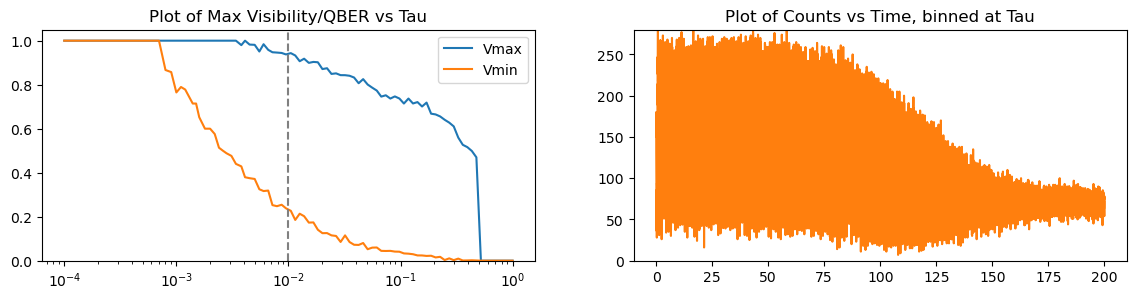

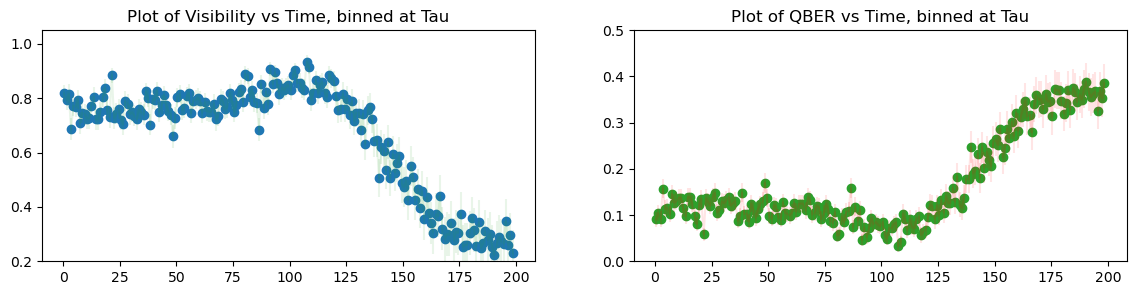

In [578]:
values1VoaRmp=AnalyseMeasurement(ms,0,100,0.01,1,secondhalf=True)

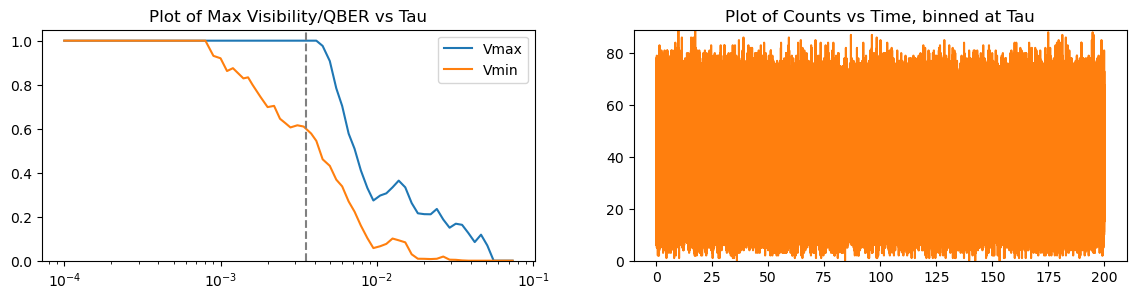

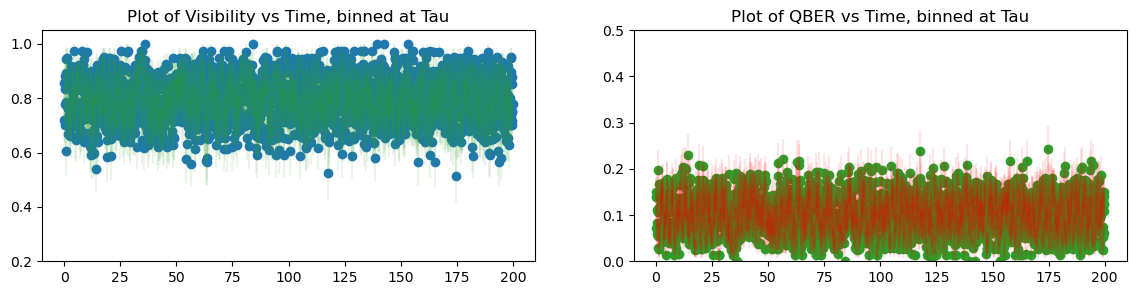

In [745]:
values100noM=AnalyseMeasurement(ms,8,100,0.0035,0.08,secondhalf=True)

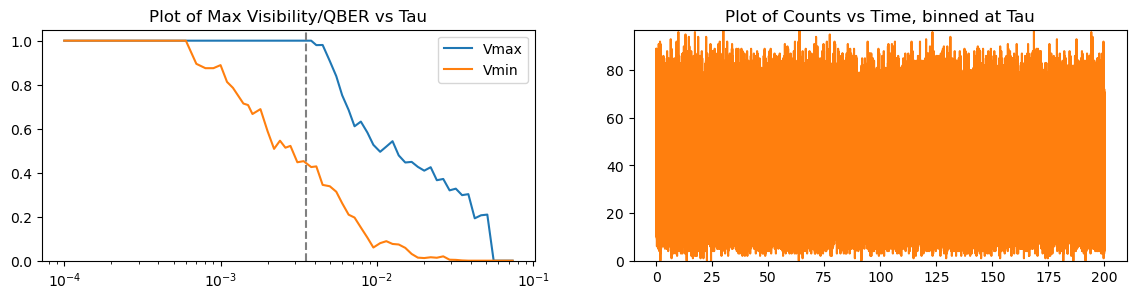

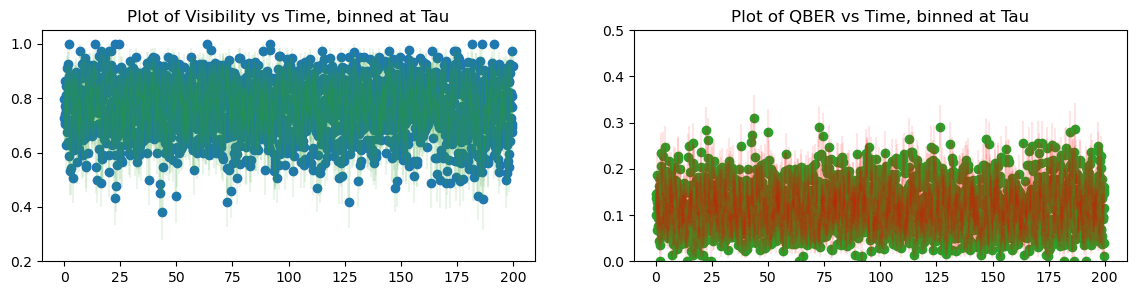

In [744]:
values100Emu=AnalyseMeasurement(ms,9,100,0.0035,0.08,secondhalf=True)

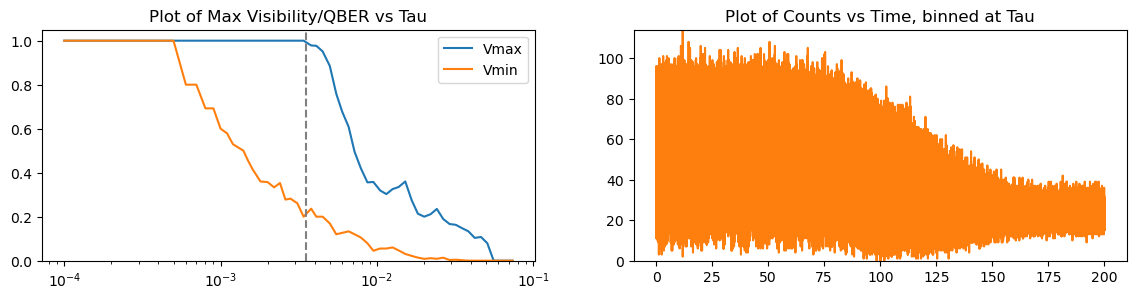

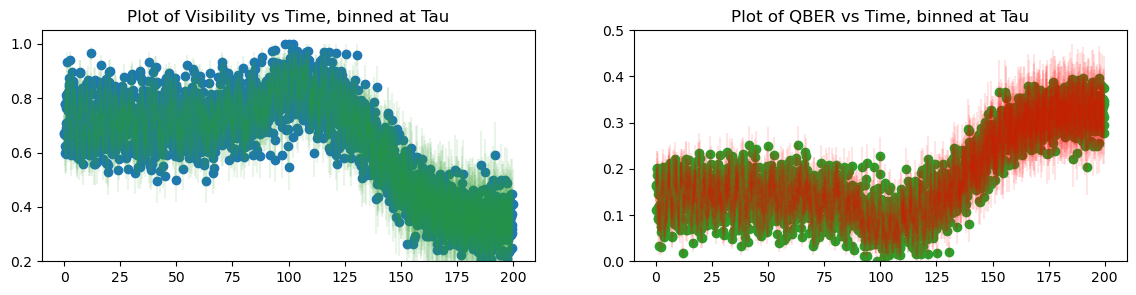

In [748]:
values100VoaRm=AnalyseMeasurement(ms,2,100,0.0035,0.08,secondhalf=True)

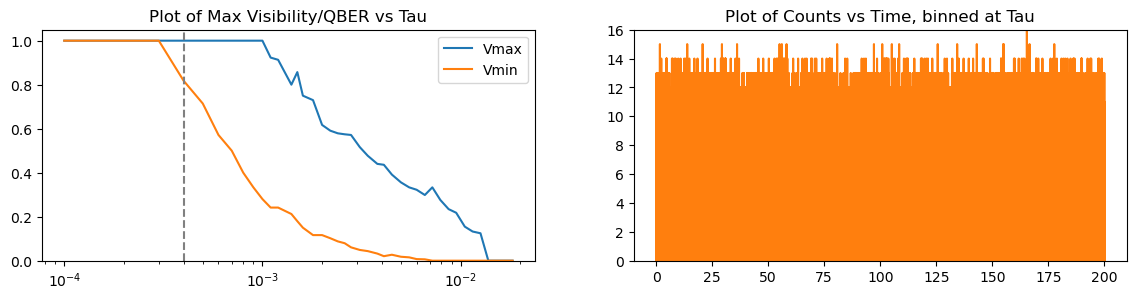

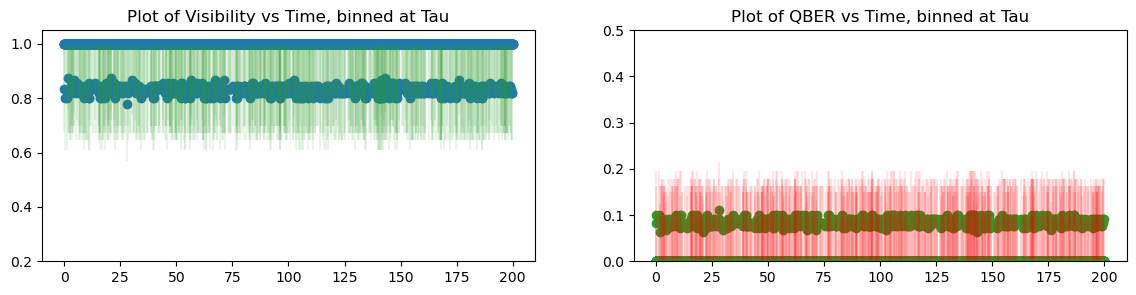

In [841]:
values1000noM=AnalyseMeasurement(ms,10,100,0.0004,0.02,secondhalf=True)

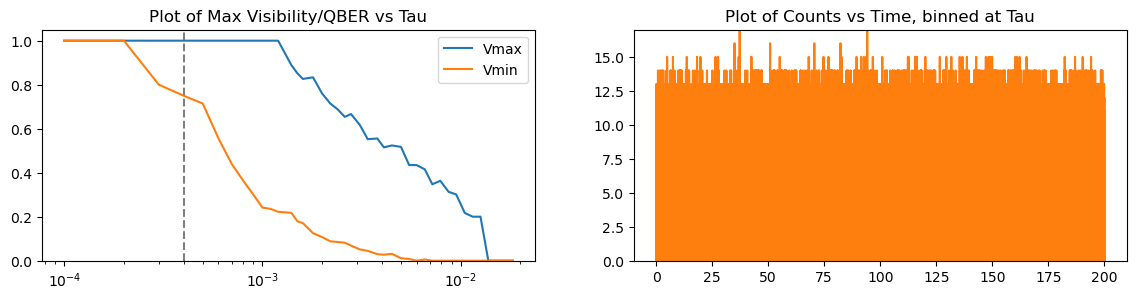

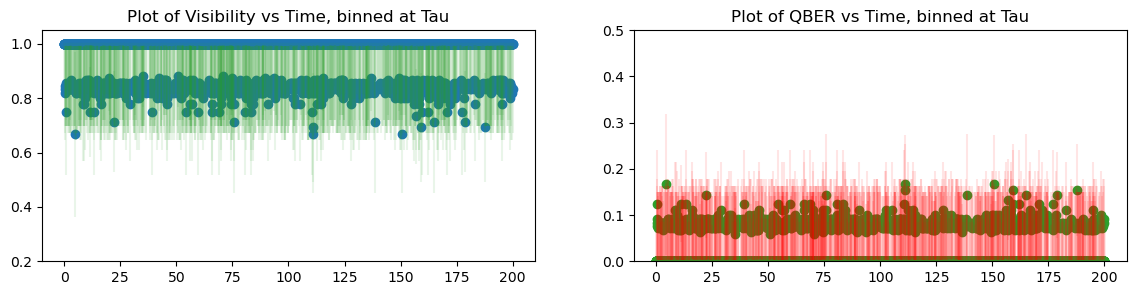

In [840]:
values1000Emu=AnalyseMeasurement(ms,11,100,0.0004,0.02,secondhalf=True)

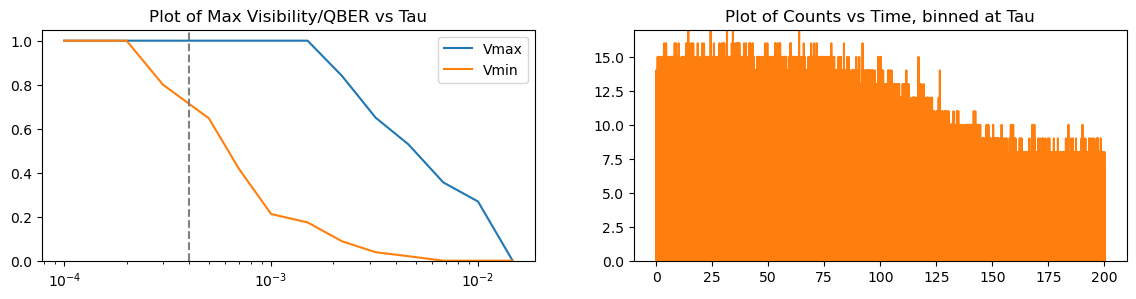

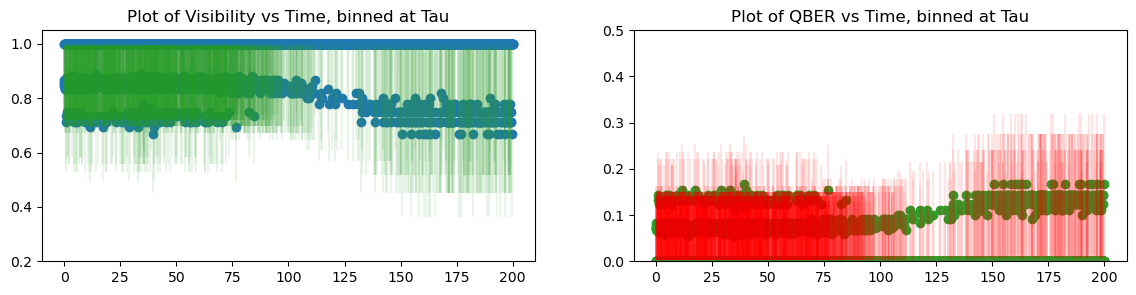

In [839]:
values1000voaRmp=AnalyseMeasurement(ms,3,25,0.0004,0.02,secondhalf=True)

In [ ]:
#UseVOAramp for tuning

In [23]:
import numpy as np
from typing import Tuple, Optional

def lockin_visibility_vs_time(
    ts,
    counts,
    f_ramp: float,
    tau: float,
    step: Optional[float] = None,
    phase_offset: float = 0.0,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Estimate time-dependent visibility V(t) using a lock-in style estimator
    for a known linear phase ramp.

    Phase model
    -----------
    phi(t) = 2*pi*f_ramp*(t - t0) + phase_offset    (mod 2*pi)

    where t0 = ts[0]. Only relative times matter.

    Parameters
    ----------
    ts : array_like
        Timestamps in seconds, 1D, monotonically increasing.
    counts : array_like
        Photon counts (or weights) for each timestamp, same length as ts.
    f_ramp : float
        Phase ramp frequency in Hz (number of 0→2π sweeps per second).
    tau : float
        Window length in seconds for estimating V(t).
    step : float or None, optional
        Step between consecutive windows in seconds. If None, use tau/2 (50% overlap).
    phase_offset : float, optional
        Additional constant phase offset in radians.

    Returns
    -------
    t_centers : np.ndarray
        Center time of each window (in seconds, same units as ts).
    V : np.ndarray
        Estimated visibility in each window.
    """
    ts = np.asarray(ts, dtype=float)
    x  = np.asarray(counts, dtype=float)

    if ts.ndim != 1 or x.ndim != 1:
        raise ValueError("ts and counts must be 1D arrays.")
    if ts.size != x.size:
        raise ValueError("ts and counts must have the same length.")
    if ts.size < 2:
        raise ValueError("Need at least 2 samples.")
    if tau <= 0:
        raise ValueError("tau must be > 0.")
    if f_ramp <= 0:
        raise ValueError("f_ramp must be > 0.")

    n = ts.size

    # Relative times (only differences matter for the phase)
    t0 = ts[0]
    trel = ts - t0

    # Approximate mean dt for index-based windows
    dts = np.diff(ts)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps must be strictly increasing.")
    dt_mean = float(np.mean(dt_pos))

    # Number of samples in a tau-window
    K_win = max(1, int(round(tau / dt_mean)))

    # Step in samples
    if step is None:
        step_s = tau / 2.0  # 50% overlap
    else:
        if step <= 0:
            raise ValueError("step must be > 0.")
        step_s = float(step)
    K_step = max(1, int(round(step_s / dt_mean)))

    # Compute phase at each sample
    phi = 2.0 * np.pi * f_ramp * trel + phase_offset

    # Precompute cos/sin and cumulative sums for efficient sliding windows
    cphi = np.cos(phi)
    sphi = np.sin(phi)

    # Weighted by counts
    cx = x * cphi
    sx = x * sphi

    Cs = np.concatenate(([0.0], np.cumsum(cx, dtype=float)))  # cumulative sum of c*x
    Ss = np.concatenate(([0.0], np.cumsum(sx, dtype=float)))  # cumulative sum of s*x
    Ns = np.concatenate(([0.0], np.cumsum(x, dtype=float)))   # cumulative sum of counts

    # Window starts/ends in index space
    if n < K_win:
        return np.array([]), np.array([])

    last_start = n - K_win
    starts = np.arange(0, last_start + 1, K_step, dtype=int)
    ends = starts + K_win

    t_centers = np.empty_like(starts, dtype=float)
    V = np.full_like(starts, np.nan, dtype=float)

    for i, (s, e) in enumerate(zip(starts, ends)):
        # Counts in this window
        N = Ns[e] - Ns[s]
        if N <= 0:
            continue

        # Lock-in sums
        C = Cs[e] - Cs[s]
        S = Ss[e] - Ss[s]

        # Visibility estimator: V ~ 2 * |first harmonic| / DC
        amp = np.sqrt(C * C + S * S)
        V[i] = 2.0 * amp / N

        # Window center time (in original absolute units)
        t_centers[i] = 0.5 * (ts[s] + ts[e - 1])

    return t_centers, V


In [25]:
import numpy as np
from typing import Tuple, Optional

def lockin_visibility_vs_time(
    ts,
    counts,
    f_ramp: float,
    tau: float,
    step: Optional[float] = None,
    phase_offset: float = 0.0,
    n_min: int = 100,      # minimum total counts per window to accept
    clip: bool = True,     # clip V to [0,1]
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Estimate time-dependent visibility V(t) using a sinusoidal fit
    for a known linear phase ramp.

    Model in each window:
        y(t) ≈ a + b cos(phi(t)) + c sin(phi(t)),
        V = sqrt(b^2 + c^2) / a

    Phase model
    -----------
    phi(t) = 2*pi*f_ramp*(t - t0) + phase_offset    (mod 2*pi)

    where t0 = ts[0]. Only relative times matter.

    Parameters
    ----------
    ts : array_like
        Timestamps in seconds, 1D, monotonically increasing.
    counts : array_like
        Photon counts for each timestamp, same length as ts.
    f_ramp : float
        Phase ramp frequency in Hz (0→2π sweeps per second).
    tau : float
        Window length in seconds for estimating V(t).
        You usually want tau to be an integer multiple of 1/f_ramp.
    step : float or None, optional
        Step between consecutive windows in seconds.
        If None, use tau/2 (50% overlap).
    phase_offset : float, optional
        Additional constant phase offset in radians.
    n_min : int, optional
        Minimum total counts in a window to accept a visibility estimate.
        Windows with fewer counts get V = NaN.
    clip : bool, optional
        If True, clip the visibility into [0, 1].

    Returns
    -------
    t_centers : np.ndarray
        Center time of each window.
    V : np.ndarray
        Estimated visibility in each window (NaN where not enough counts).
    """
    ts = np.asarray(ts, dtype=float)
    y  = np.asarray(counts, dtype=float)

    if ts.ndim != 1 or y.ndim != 1:
        raise ValueError("ts and counts must be 1D arrays.")
    if ts.size != y.size:
        raise ValueError("ts and counts must have the same length.")
    if ts.size < 2:
        raise ValueError("Need at least 2 samples.")
    if tau <= 0:
        raise ValueError("tau must be > 0.")
    if f_ramp <= 0:
        raise ValueError("f_ramp must be > 0.")

    n = ts.size

    # Relative times (only differences matter for the phase)
    t0 = ts[0]
    trel = ts - t0

    # Approximate mean dt for index-based windows
    dts = np.diff(ts)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps must be strictly increasing.")
    dt_mean = float(np.mean(dt_pos))

    # Number of samples in a tau-window
    K_win = max(1, int(round(tau / dt_mean)))

    # Step in samples
    if step is None:
        step_s = tau / 2.0  # 50% overlap
    else:
        if step <= 0:
            raise ValueError("step must be > 0.")
        step_s = float(step)
    K_step = max(1, int(round(step_s / dt_mean)))

    if n < K_win:
        return np.array([]), np.array([])

    # Compute phase at each sample
    phi = 2.0 * np.pi * f_ramp * trel + phase_offset
    cphi = np.cos(phi)
    sphi = np.sin(phi)

    # Window starts/ends in index space
    last_start = n - K_win
    starts = np.arange(0, last_start + 1, K_step, dtype=int)
    ends = starts + K_win

    t_centers = np.empty_like(starts, dtype=float)
    V = np.full_like(starts, np.nan, dtype=float)

    for i, (s, e) in enumerate(zip(starts, ends)):
        y_win = y[s:e]
        if y_win.size == 0:
            continue

        N_tot = np.sum(y_win)
        if N_tot < n_min:
            # Not enough counts -> unreliable; leave V as NaN
            t_centers[i] = 0.5 * (ts[s] + ts[e - 1])
            continue

        c_win = cphi[s:e]
        s_win = sphi[s:e]

        # Design matrix: [1, cos(phi), sin(phi)]
        X = np.column_stack((np.ones_like(c_win), c_win, s_win))

        # Least-squares fit: y ≈ a + b cos + c sin
        # (we treat each sample equally; you could add weights if desired)
        beta, *_ = np.linalg.lstsq(X, y_win, rcond=None)
        a, b, c = beta

        # Require positive DC level
        if a <= 0:
            V[i] = np.nan
        else:
            amp = np.sqrt(b * b + c * c)
            v = amp / a
            if clip:
                v = max(0.0, min(1.0, v))
            V[i] = v

        # Window center time
        t_centers[i] = 0.5 * (ts[s] + ts[e - 1])

    return t_centers, V


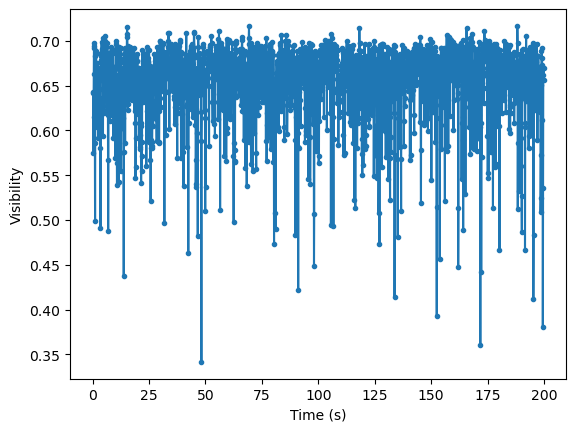

In [49]:
f_ramp = 1000.0      # Hz
m = 200              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=8
t_centersnm100, Vnm100, Verrnm100 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,       # overlap windows
    n_min=100,
    clip=True,)
plt.plot(t_centersnm100, Vnm100, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

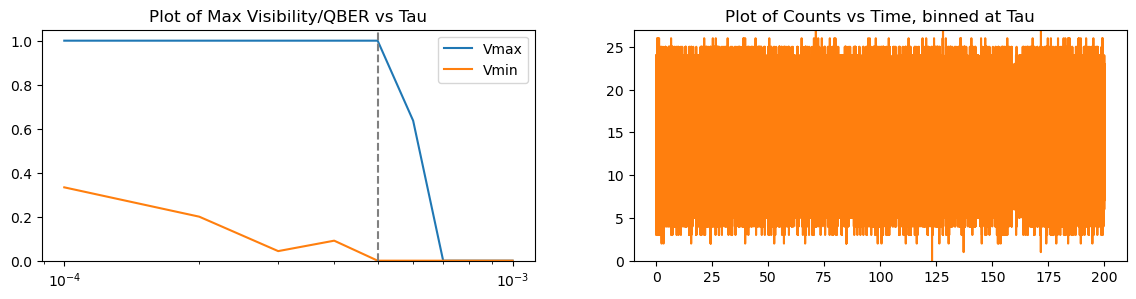

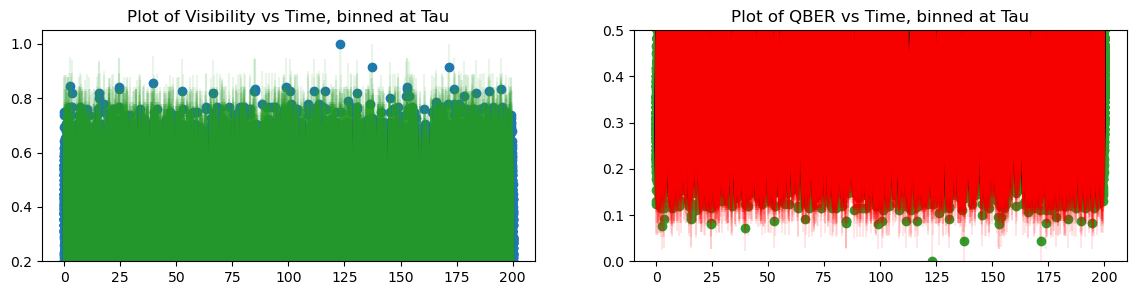

In [53]:
values10noM=AnalyseMeasurement(ms,8,1000,0.0005,0.001,secondhalf=True)

In [1242]:
f_ramp = 100.0      # Hz
m = 20              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=9
t_centersEmu100, VEmu100, VerrEmu100 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,       # overlap windows
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1244]:
f_ramp = 100.0      # Hz
m = 20              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=2
t_centerVOARmp100, VVOARmp100, VerrVOARmp100 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,       # overlap windows
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1272]:
#plt.errorbar(t_centerVOARmp100, VVOARmp100,yerr=VerrVOARmp100,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm100, Vnm100,yerr=Verrnm100,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu100, VEmu100,yerr=VerrEmu100,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.title('Plot of Estimated Visibility vs Time, Ramp 100Hz')
plt.legend()

In [1250]:
QBERnm100=(1-Vnm100)/2
QBERernm100=0.5*Verrnm100
QBEREmu100=(1-VEmu100)/2
QBERerEmu100=0.5*VerrEmu100
QBERVOARmp100=(1-VVOARmp100)/2
QBERerVOARmp100=0.5*VerrVOARmp100

In [1274]:
#plt.errorbar(t_centerVOARmp100, QBERVOARmp100,yerr=QBERerVOARmp100,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm100, QBERnm100,yerr=QBERernm100,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu100, QBEREmu100,yerr=QBERerEmu100,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER (%)')
plt.title('Plot of Estimated QBER vs Time, Ramp 100Hz')
plt.legend()

In [1150]:
f_ramp = 1000.0      # Hz
m = 200              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=10
t_centersnm1000, Vnm1000, Verrnm1000 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1152]:
f_ramp = 1000.0      # Hz
m = 200              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=11
t_centersEmu1000, VEmu1000, VerrEmu1000 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1154]:
f_ramp = 1000.0      # Hz
m = 200              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=3
t_centerVOARmp1000, VVOARmp1000, VerrVOARmp1000 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1276]:
#plt.errorbar(t_centerVOARmp1000, VVOARmp1000,yerr=VerrVOARmp1000,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm1000, Vnm1000,yerr=Verrnm1000,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu1000, VEmu1000,yerr=VerrEmu1000,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.title('Plot of Estimated Visibility vs Time, Ramp 1000Hz')
plt.legend()

In [1254]:
QBERnm1000=(1-Vnm1000)/2
QBERernm1000=0.5*Verrnm1000
QBEREmu1000=(1-VEmu1000)/2
QBERerEmu1000=0.5*VerrEmu1000
QBERVOARmp1000=(1-VVOARmp1000)/2
QBERerVOARmp1000=0.5*VerrVOARmp1000

In [1278]:
#plt.errorbar(t_centerVOARmp1000, QBERVOARmp1000,yerr=QBERerVOARmp1000,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm1000, QBERnm1000,yerr=QBERernm1000,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu1000, QBEREmu1000,yerr=QBERerEmu1000,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')

plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER (%)')
plt.title('Plot of Estimated QBER vs Time, Ramp 1000Hz')
plt.legend()

In [1162]:
f_ramp = 10.0      # Hz
m = 2              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=6
t_centersnm10, Vnm10, Verrnm10 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1164]:
f_ramp = 10.0      # Hz
m = 2              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=7
t_centersEmu10, VEmu10, VerrEmu10 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1169]:
f_ramp = 10.0      # Hz
m = 2              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=1
t_centerVOARmp10, VVOARmp10, VerrVOARmp10 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1280]:
#plt.errorbar(t_centerVOARmp10, VVOARmp10,yerr=VerrVOARmp10,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm10, Vnm10,yerr=Verrnm10,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu10, VEmu10,yerr=VerrEmu10,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.title('Plot of Estimated Visibility vs Time, Ramp 10Hz')
plt.legend()

In [1258]:
QBERnm10=(1-Vnm10)/2
QBERernm10=0.5*Verrnm10
QBEREmu10=(1-VEmu10)/2
QBERerEmu10=0.5*VerrEmu10
QBERVOARmp10=(1-VVOARmp10)/2
QBERerVOARmp10=0.5*VerrVOARmp10

In [1282]:
#plt.errorbar(t_centerVOARmp10, QBERVOARmp10,yerr=QBERerVOARmp10,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm10, QBERnm10,yerr=QBERernm10,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu10, QBEREmu10,yerr=QBERerEmu10,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER (%)')
plt.title('Plot of Estimated QBER vs Time, Ramp 10Hz')
plt.legend()

In [1220]:
f_ramp = 1.0      # Hz
m = 1.0              # 200 periods per window
tau = 1     # 0.2 s
j=4
t_centersnm1, Vnm1, Verrnm1 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centersnm1, Vnm1, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1222]:
f_ramp = 1.0      # Hz
m = 1              # 200 periods per window
tau = 1     # 0.2 s
j=5
t_centersEmu1, VEmu1, VerrEmu1 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centersEmu1, VEmu1, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1224]:
f_ramp = 1.0      # Hz
m = 1              # 200 periods per window
tau = m / f_ramp     # 0.2 s
j=0
t_centerVOARmp1, VVOARmp1, VerrVOARmp1 = lockin_visibility_vs_time(
    timestamps_to_elapsed_seconds(ms[j]['data']['timestamps']), ms[j]['data']['counts'], f_ramp, tau,
    n_min=100,
    clip=True,)
plt.plot(t_centers, V, marker='.')
plt.xlabel("Time (s)")
plt.ylabel("Visibility")
plt.show()

In [1284]:
#plt.errorbar(t_centerVOARmp1, VVOARmp1,yerr=VerrVOARmp1,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm1, Vnm1,yerr=Verrnm1,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu1, VEmu1,yerr=VerrEmu1,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.title('Plot of Estimated Visibility vs Time, Ramp 1Hz')
plt.legend()

In [1262]:
QBERnm1=(1-Vnm1)/2
QBERernm1=0.5*Verrnm1
QBEREmu1=(1-VEmu1)/2
QBERerEmu1=0.5*VerrEmu1
QBERVOARmp1=(1-VVOARmp1)/2
QBERerVOARmp1=0.5*VerrVOARmp1

In [1286]:
#plt.errorbar(t_centerVOARmp1, QBERVOARmp1,yerr=QBERerVOARmp1,linestyle='',fmt='s', ms=3.5, label='VOA Voltage Ramp')
plt.errorbar(t_centersnm1, QBERnm1,yerr=QBERernm1,linestyle='',fmt='s', ms=3.5, label='No VOA, reference')
plt.errorbar(t_centersEmu1, QBEREmu1,yerr=QBERerEmu1,linestyle='',fmt='s', ms=3.5, label='Free-space Channel Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER (%)')
plt.title('Plot of Estimated QBER vs Time, Ramp 1Hz')
plt.legend()

In [1298]:
ps=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\psfixed.npy')
vs=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\vsfixed.npy')

In [1312]:
plt.errorbar(t_centerVOARmp1000, VVOARmp1000,yerr=VerrVOARmp1000,linestyle='',fmt='s', ms=3.5, label='PM Ramp 1000Hz')
plt.errorbar(t_centerVOARmp100, VVOARmp100,yerr=VerrVOARmp100,linestyle='',fmt='s', ms=3.5, label='PM Ramp 100Hz')
plt.errorbar(t_centerVOARmp10, VVOARmp10,yerr=VerrVOARmp10,linestyle='',fmt='s', ms=3.5, label='PM Ramp 10Hz')
plt.errorbar(t_centerVOARmp1, VVOARmp1,yerr=VerrVOARmp1,linestyle='',fmt='s', ms=3.5, label='PM Ramp 1Hz')
#psnew=(ps/np.max(ps))
#psnew2=(np.max(psnew)-psnew)/(np.max(psnew)+np.min(psnew))
#psnew2=(psnew*0.6)
#vsnew=(vs*40)*(547.3046329999999/501)
#plt.plot(vsnew,psnew2,color='black', label='Optical Power*0.4/VOA Voltage')

plt.xlabel('Time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.title('Plot of Estimated Visibility vs Time, VOA Ramps')
plt.legend()

In [1295]:
plt.errorbar(t_centerVOARmp1000, QBERVOARmp1000,yerr=QBERerVOARmp1000,linestyle='',fmt='s', ms=3.5, label='PM Ramp 1000Hz')
plt.errorbar(t_centerVOARmp100, QBERVOARmp100,yerr=QBERerVOARmp100,linestyle='',fmt='s', ms=3.5, label='PM Ramp 100Hz')
plt.errorbar(t_centerVOARmp10, QBERVOARmp10,yerr=QBERerVOARmp10,linestyle='',fmt='s', ms=3.5, label='PM Ramp 10Hz')
plt.errorbar(t_centerVOARmp1, QBERVOARmp1,yerr=QBERerVOARmp1,linestyle='',fmt='s', ms=3.5, label='PM Ramp 1Hz')


plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER (%)')
plt.title('Plot of Estimated QBERs vs Time, QBER Ramps')
plt.legend()

In [1025]:
def load_measurements2(base_dir: str, verbose: bool=False) -> List[Dict[str, Any]]:
    """
    Scans base_dir/YYYY-MM-DD/subfolder for triplets:
      <base>_<STAMP>*.npz
      <base>_<STAMP>*.csv
      <base>_<STAMP>*_meta.txt
    Uses the *last* stamp occurrence in the filename. Returns newest→oldest.
    """
    root = base_dir
    if not os.path.isdir(root):
        raise FileNotFoundError(f"Folder not found: {root}")

    recs: Dict[tuple, Dict[str, Any]] = {}
    for fn in os.listdir(root):
        full = os.path.join(root, fn)
        if not os.path.isfile(full): 
            if verbose: print("[skip dir]", fn)
            continue

        matches = list(STAMP_ANY.finditer(fn))
        if not matches:
            if verbose: print("[no stamp]", fn)
            continue
        m = matches[-1]                      # use the last stamp in the name
        stamp_str = m.group(1)
        stamp_dt  = _parse_stamp(stamp_str)
        if not stamp_dt:
            if verbose: print("[bad stamp]", fn, "|", stamp_str)
            continue

        base = fn[:m.start()]                # everything before the stamp
        kind = None
        if fn.endswith("_meta.txt"): kind = "meta"
        else:
            _, ext = os.path.splitext(fn)
            ext = ext.lower()
            if ext == ".npz": kind = "npz"
            elif ext == ".csv": kind = "csv"
        if not kind:
            if verbose: print("[unknown ext]", fn)
            continue

        key = (base, stamp_dt)
        rec = recs.setdefault(key, {"base": base.rstrip("_"), "stamp": stamp_dt, "npz": None, "csv": None, "meta": None})
        rec[kind] = full

    entries = sorted(recs.values(), key=lambda d: d["stamp"], reverse=True)

    out: List[Dict[str, Any]] = []
    for g in entries:
        data: Dict[str, Any] = {}
        meta: Dict[str, Any] = {}
        if g["npz"]:
            try: data = _load_from_npz(g["npz"])
            except Exception as e:
                if verbose: print("[npz load fail]", g["npz"], e)
        if not data and g["csv"]:
            try: data = _load_from_csv(g["csv"])
            except Exception as e:
                if verbose: print("[csv load fail]", g["csv"], e)
        if g["meta"]:
            try: meta = _load_meta(g["meta"])
            except Exception as e:
                if verbose: print("[meta load fail]", g["meta"], e)

        out.append({
            "name": g["base"],
            "timestamp": g["stamp"],   # tz-aware datetime
            "npz_path": g["npz"],
            "csv_path": g["csv"],
            "meta_path": g["meta"],
            "data": data,
            "meta": meta,
        })
    if verbose:
        print(f"Loaded {len(out)} measurements from {root}")
    return out


In [1029]:
ms2 = load_measurements2(base_dir=r"D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\1mhz", verbose=True)


Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\1mhz


In [1049]:
IdGate_1MHz_ts=timestamps_to_elapsed_seconds(ms2[0]['data']['timestamps'])
IdGate_1MHz_cts=ms2[0]['data']['counts']

In [1051]:
mstemp = load_measurements2(base_dir=r"D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\2mhz", verbose=True)
IdGate_2MHz_ts=timestamps_to_elapsed_seconds(mstemp[0]['data']['timestamps'])
IdGate_2MHz_cts=mstemp[0]['data']['counts']

Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\2mhz


In [1053]:
mstemp = load_measurements2(base_dir=r"D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\5mhz", verbose=True)
IdGate_5MHz_ts=timestamps_to_elapsed_seconds(mstemp[0]['data']['timestamps'])
IdGate_5MHz_cts=mstemp[0]['data']['counts']

Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\5mhz


In [1055]:
mstemp = load_measurements2(base_dir=r"D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\10mhz", verbose=True)
IdGate_10MHz_ts=timestamps_to_elapsed_seconds(mstemp[0]['data']['timestamps'])
IdGate_10MHz_cts=mstemp[0]['data']['counts']

Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\10mhz


In [1057]:
mstemp = load_measurements2(base_dir=r"D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\20mhz", verbose=True)
IdGate_20MHz_ts=timestamps_to_elapsed_seconds(mstemp[0]['data']['timestamps'])
IdGate_20MHz_cts=mstemp[0]['data']['counts']

Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\20mhz


In [1059]:
"""
Diagnostics script for IDQube measurements at different gate frequencies.

For each dataset (time series of counts at a given gate frequency), it will:
  A) Test how "Poisson-like" the counts are (Fano factor, chi-square vs Poisson).
  B) Compute the count rate (counts/s).

For multiple datasets taken at different gate frequencies (with constant optical power),
it will also:
  - Check whether the count rate increases with gate frequency.
  - Check how linear the scaling is.

Usage:
  - Fill in the `datasets` list in the __main__ section with your data.
  - Run: `python check_idqube_poisson_and_scaling.py`
"""

import math
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np

# Optional: scipy for chi-square p-values
try:
    from scipy.stats import chi2
    _HAS_SCIPY = True
except ImportError:  # pragma: no cover
    _HAS_SCIPY = False


@dataclass
class PoissonDiagnostics:
    mean: float
    variance: float
    fano_factor: float
    chi2: Optional[float]
    dof: Optional[int]
    p_value: Optional[float]
    n_samples: int
    max_count: int


@dataclass
class DatasetDiagnostics:
    label: str
    gate_freq_hz: float
    duration_s: float
    total_counts: int
    rate_hz: float
    poisson: PoissonDiagnostics


def poisson_diagnostics(counts: np.ndarray, max_k: Optional[int] = None) -> PoissonDiagnostics:
    """
    Basic Poisson-ness checks for an array of non-negative integer counts.

    - Computes mean, variance, Fano factor.
    - Performs a chi-square goodness-of-fit test against Poisson(lambda=mean),
      if scipy is available. Otherwise, returns chi2=None, p_value=None.

    Parameters
    ----------
    counts : np.ndarray
        1D array of non-negative integers.
    max_k : int or None
        Maximum count value to include in the chi-square test.
        If None, choose based on data.

    Returns
    -------
    PoissonDiagnostics
    """
    counts = np.asarray(counts, dtype=float)
    if counts.ndim != 1:
        raise ValueError("counts must be a 1D array.")
    if counts.size == 0:
        raise ValueError("counts array is empty.")

    if np.any(counts < 0):
        raise ValueError("counts must be non-negative.")

    # Ideally these are integers, but we don't strictly enforce that.
    n = counts.size
    mean = float(np.mean(counts))
    var = float(np.var(counts, ddof=1)) if n > 1 else float("nan")
    fano = var / mean if mean > 0 else float("nan")
    k_max_data = int(np.max(counts))

    if max_k is None:
        # Limit to mean + 6*sqrt(mean) or max observed, whichever is smaller
        if mean > 0:
            k_lim = int(math.ceil(mean + 6.0 * math.sqrt(mean)))
            max_k = min(k_lim, k_max_data)
        else:
            max_k = k_max_data

    # Build histogram for k = 0..max_k
    ks = np.arange(0, max_k + 1, dtype=int)
    hist_obs, _ = np.histogram(counts, bins=np.arange(-0.5, max_k + 1.5, 1.0))

    # Poisson expected frequencies
    if mean <= 0:
        chi2_val = None
        dof = None
        p_val = None
    else:
        lam = mean
        # Compute Poisson pmf carefully for k up to max_k
        # p(k) = exp(-lam) * lam^k / k!
        # To reduce underflow, accumulate log-pmf then exponentiate.
        log_p = ks * np.log(lam) - lam - np.array([math.lgamma(k + 1) for k in ks])
        p = np.exp(log_p)
        p /= p.sum()  # renormalize (finite truncation)

        expected = n * p

        # Exclude bins with too small expected counts (<~5) from chi-square
        mask = expected > 1e-6  # very small cutoff first
        # (You can tighten this to >5 if you want a more classical chi-square rule.)
        ks_use = ks[mask]
        obs_use = hist_obs[mask]
        exp_use = expected[mask]

        # Avoid zero expected bins
        nonzero = exp_use > 0
        obs_use = obs_use[nonzero]
        exp_use = exp_use[nonzero]

        dof = obs_use.size - 1 - 1  # minus 1 for sum constraint, minus 1 for estimated lambda
        if dof <= 0 or obs_use.size == 0:
            chi2_val = None
            p_val = None
        else:
            chi2_val = float(np.sum((obs_use - exp_use) ** 2 / exp_use))
            if _HAS_SCIPY:
                p_val = float(chi2.sf(chi2_val, dof))
            else:
                p_val = None  # user can interpret chi2_val & dof manually

    return PoissonDiagnostics(
        mean=mean,
        variance=var,
        fano_factor=fano,
        chi2=chi2_val,
        dof=dof,
        p_value=p_val,
        n_samples=n,
        max_count=k_max_data,
    )


def analyze_single_dataset(
    times: np.ndarray,
    counts: np.ndarray,
    gate_freq_hz: float,
    label: str = "",
) -> DatasetDiagnostics:
    """
    Analyze one measurement at a given gate frequency.

    Parameters
    ----------
    times : np.ndarray
        1D array of timestamps in seconds (monotonically increasing).
    counts : np.ndarray
        1D array of counts (same length as times).
    gate_freq_hz : float
        Gate frequency in Hz for this measurement.
    label : str
        Label/name for this dataset (e.g. "1 MHz").

    Returns
    -------
    DatasetDiagnostics
    """
    times = np.asarray(times, dtype=float)
    counts = np.asarray(counts, dtype=float)

    if times.ndim != 1 or counts.ndim != 1:
        raise ValueError("times and counts must be 1D arrays.")
    if times.size != counts.size:
        raise ValueError("times and counts must have the same length.")
    if times.size < 2:
        raise ValueError("Need at least 2 samples.")

    if not np.all(np.diff(times) > 0):
        raise ValueError("times must be strictly increasing.")

    duration = float(times[-1] - times[0])
    if duration <= 0:
        raise ValueError("Non-positive duration.")

    total_counts = int(np.sum(counts))
    rate = total_counts / duration

    pois = poisson_diagnostics(counts)

    return DatasetDiagnostics(
        label=label or f"{gate_freq_hz/1e6:.2f} MHz",
        gate_freq_hz=gate_freq_hz,
        duration_s=duration,
        total_counts=total_counts,
        rate_hz=rate,
        poisson=pois,
    )


def analyze_scaling(datasets: List[DatasetDiagnostics]) -> Dict[str, float]:
    """
    Given a list of DatasetDiagnostics (different gate frequencies),
    analyze how count rate scales with gate frequency.

    Returns a dict with:
        - corr_gate_rate: Pearson correlation between gate_freq and rate
        - slope_rate_per_hz: linear fit slope (rate vs gate_freq)
        - intercept_rate: linear fit intercept
        - mean_rate_per_gate: average (rate / gate_freq)
    """
    if len(datasets) < 2:
        raise ValueError("Need at least two datasets to analyze scaling.")

    freqs = np.array([d.gate_freq_hz for d in datasets], dtype=float)
    rates = np.array([d.rate_hz for d in datasets], dtype=float)

    # Linear fit: rate = m * gate_freq + b
    A = np.column_stack((freqs, np.ones_like(freqs)))
    m, b = np.linalg.lstsq(A, rates, rcond=None)[0]

    # Pearson correlation
    corr = float(np.corrcoef(freqs, rates)[0, 1])

    # Rate per gate
    rate_per_gate = rates / freqs
    mean_rate_per_gate = float(np.mean(rate_per_gate))

    return {
        "corr_gate_rate": corr,
        "slope_rate_per_hz": float(m),
        "intercept_rate": float(b),
        "mean_rate_per_gate": mean_rate_per_gate,
    }


def print_dataset_report(ds: DatasetDiagnostics) -> None:
    """Pretty-print diagnostics for a single dataset."""
    print(f"\n=== Dataset: {ds.label} ===")
    print(f"Gate frequency: {ds.gate_freq_hz:.3e} Hz")
    print(f"Duration:       {ds.duration_s:.3f} s")
    print(f"Total counts:   {ds.total_counts}")
    print(f"Count rate:     {ds.rate_hz:.3f} counts/s")

    p = ds.poisson
    print("\n[Poisson diagnostics]")
    print(f"  N samples:   {p.n_samples}")
    print(f"  Mean:        {p.mean:.4f}")
    print(f"  Variance:    {p.variance:.4f}")
    print(f"  Fano factor: {p.fano_factor:.4f}  (≈1 for ideal Poisson)")
    print(f"  Max count:   {p.max_count}")

    if p.chi2 is not None and p.dof is not None:
        print(f"  Chi-square:  {p.chi2:.3f} (dof={p.dof})")
        if p.p_value is not None:
            print(f"  p-value:     {p.p_value:.3g}")
        else:
            print("  p-value:     (install scipy to compute)")
    else:
        print("  Chi-square test not computed (insufficient data or lambda<=0).")


def print_scaling_report(datasets: List[DatasetDiagnostics]) -> None:
    """Pretty-print the scaling of count rate with gate frequency."""
    print("\n=== Gate frequency scaling ===")
    for ds in datasets:
        print(f"{ds.label:>10s}: f_gate = {ds.gate_freq_hz/1e6:6.2f} MHz, "
              f"rate = {ds.rate_hz:9.2f} counts/s, "
              f"rate/f_gate = {ds.rate_hz/ds.gate_freq_hz: .3e} counts/gate")

    stats = analyze_scaling(datasets)
    print("\n[Linear scaling analysis: rate ≈ m * f_gate + b]")
    print(f"  Pearson corr(rate, f_gate): {stats['corr_gate_rate']:.4f}")
    print(f"  Slope m (counts/s per Hz):  {stats['slope_rate_per_hz']:.4e}")
    print(f"  Intercept b (counts/s):     {stats['intercept_rate']:.3f}")
    print(f"  Mean rate per gate:         {stats['mean_rate_per_gate']:.3e} counts/gate")

    print("\nInterpretation hints:")
    print("  - If corr ≈ 1 and rate/f_gate is ~constant, "
          "then counts scale linearly with gate frequency "
          "(no obvious saturation).")
    print("  - If rate/f_gate decreases at higher gate frequencies, "
          "you may be hitting dead-time or saturation effects.")

In [1071]:
times_1MHz = IdGate_20MHz_ts   # 1D numpy array of timestamps in seconds
counts_1MHz = IdGate_20MHz_cts  # 1D numpy array of counts (same length)
gate_freq_1MHz = 20e6

ds_1MHz = analyze_single_dataset(times_1MHz, counts_1MHz,
                                 gate_freq_hz=gate_freq_1MHz,
                                 label="20.0 MHz")
datasets.append(ds_1MHz)


In [1073]:
for ds in datasets:
    print_dataset_report(ds)

print_scaling_report(datasets)


=== Dataset: 1.0 MHz ===
Gate frequency: 1.000e+06 Hz
Duration:       30.000 s
Total counts:   194136
Count rate:     6471.222 counts/s

[Poisson diagnostics]
  N samples:   300000
  Mean:        0.6471
  Variance:    0.5331
  Fano factor: 0.8238  (≈1 for ideal Poisson)
  Max count:   4
  Chi-square:  4871.020 (dof=3)
  p-value:     0

=== Dataset: 2.0 MHz ===
Gate frequency: 2.000e+06 Hz
Duration:       30.000 s
Total counts:   348099
Count rate:     11603.339 counts/s

[Poisson diagnostics]
  N samples:   300000
  Mean:        1.1603
  Variance:    0.8134
  Fano factor: 0.7010  (≈1 for ideal Poisson)
  Max count:   5
  Chi-square:  15102.962 (dof=4)
  p-value:     0

=== Dataset: 5.0 MHz ===
Gate frequency: 5.000e+06 Hz
Duration:       30.000 s
Total counts:   663750
Count rate:     22125.074 counts/s

[Poisson diagnostics]
  N samples:   300000
  Mean:        2.2125
  Variance:    1.0565
  Fano factor: 0.4775  (≈1 for ideal Poisson)
  Max count:   6
  Chi-square:  53511.360 (dof=5)

In [29]:
import numpy as np
from typing import Tuple, Optional

def lockin_visibility_vs_time(
    ts,
    counts,
    f_ramp: float,
    tau: float,
    step: Optional[float] = None,
    phase_offset: float = 0.0,
    n_min: int = 100,      # minimum total counts per window to accept
    clip: bool = True,     # clip V to [0,1]
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Estimate time-dependent visibility V(t) using a sinusoidal fit
    for a known linear phase ramp, and propagate errors to V_err(t).

    Model in each window:
        y(t) ≈ a + b cos(phi(t)) + c sin(phi(t)),
        V = sqrt(b^2 + c^2) / a

    Phase model
    -----------
    phi(t) = 2*pi*f_ramp*(t - t0) + phase_offset    (mod 2*pi)

    Parameters
    ----------
    ts : array_like
        Timestamps in seconds, 1D, monotonically increasing.
    counts : array_like
        Photon counts for each timestamp, same length as ts.
    f_ramp : float
        Phase ramp frequency in Hz (0→2π sweeps per second).
    tau : float
        Window length in seconds for estimating V(t).
    step : float or None, optional
        Step between consecutive windows in seconds.
        If None, use tau/2 (50% overlap).
    phase_offset : float, optional
        Additional constant phase offset in radians.
    n_min : int, optional
        Minimum total counts in a window to accept a visibility estimate.
        Windows with fewer counts get V = NaN, V_err = NaN.
    clip : bool, optional
        If True, clip the visibility into [0, 1].

    Returns
    -------
    t_centers : np.ndarray
        Center time of each window.
    V : np.ndarray
        Estimated visibility in each window (NaN where not enough counts).
    V_err : np.ndarray
        Approximate 1σ error on V in each window (NaN where not enough counts).
    """
    ts = np.asarray(ts, dtype=float)
    y  = np.asarray(counts, dtype=float)

    if ts.ndim != 1 or y.ndim != 1:
        raise ValueError("ts and counts must be 1D arrays.")
    if ts.size != y.size:
        raise ValueError("ts and counts must have the same length.")
    if ts.size < 2:
        raise ValueError("Need at least 2 samples.")
    if tau <= 0:
        raise ValueError("tau must be > 0.")
    if f_ramp <= 0:
        raise ValueError("f_ramp must be > 0.")

    n = ts.size

    # Relative times (only differences matter for the phase)
    t0 = ts[0]
    trel = ts - t0

    # Approximate mean dt for index-based windows
    dts = np.diff(ts)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps must be strictly increasing.")
    dt_mean = float(np.mean(dt_pos))

    # Number of samples in a tau-window
    K_win = max(1, int(round(tau / dt_mean)))

    # Step in samples
    if step is None:
        step_s = tau / 2.0  # 50% overlap
    else:
        if step <= 0:
            raise ValueError("step must be > 0.")
        step_s = float(step)
    K_step = max(1, int(round(step_s / dt_mean)))

    if n < K_win:
        return np.array([]), np.array([]), np.array([])

    # Compute phase at each sample
    phi = 2.0 * np.pi * f_ramp * trel + phase_offset
    cphi = np.cos(phi)
    sphi = np.sin(phi)

    # Window starts/ends in index space
    last_start = n - K_win
    starts = np.arange(0, last_start + 1, K_step, dtype=int)
    ends = starts + K_win

    t_centers = np.empty_like(starts, dtype=float)
    V = np.full_like(starts, np.nan, dtype=float)
    V_err = np.full_like(starts, np.nan, dtype=float)

    for i, (s, e) in enumerate(zip(starts, ends)):
        y_win = y[s:e]
        if y_win.size == 0:
            continue

        N_tot = np.sum(y_win)
        t_centers[i] = 0.5 * (ts[s] + ts[e - 1])

        if N_tot < n_min:
            # Not enough counts -> unreliable; leave NaNs
            continue

        c_win = cphi[s:e]
        s_win = sphi[s:e]

        # Design matrix: [1, cos(phi), sin(phi)]
        X = np.column_stack((np.ones_like(c_win), c_win, s_win))

        # Least-squares fit: y ≈ a + b cos + c sin
        beta, residuals, rank, svals = np.linalg.lstsq(X, y_win, rcond=None)
        a, b, c = beta

        # Require positive DC level
        if a <= 0:
            continue

        # Visibility
        amp = np.sqrt(b * b + c * c)
        v = amp / a
        if clip:
            v = max(0.0, min(1.0, v))
        V[i] = v

        # --- Error propagation ---
        # Estimate noise variance sigma^2 from residuals
        # residuals is sum of squared residuals if rank == 3, else empty
        if residuals.size > 0 and (y_win.size > X.shape[1]):
            dof = y_win.size - X.shape[1]
            sigma2 = float(residuals[0] / dof)
        else:
            # Fallback: assume sigma^2 ~ mean count (Poisson-ish)
            sigma2 = float(np.mean(y_win)) if np.mean(y_win) > 0 else 1.0

        # Covariance of [a,b,c] for homoscedastic noise
        # Cov = sigma^2 * (X^T X)^(-1)
        XT_X = X.T @ X
        try:
            Cov = sigma2 * np.linalg.inv(XT_X)
        except np.linalg.LinAlgError:
            # Ill-conditioned; skip error estimate
            continue

        # Gradient of V wrt (a,b,c)
        # r = sqrt(b^2 + c^2)
        r2 = b * b + c * c
        if r2 <= 0:
            continue
        r = np.sqrt(r2)
        V_unclipped = r / a  # use unclipped for derivatives

        dV_da = -V_unclipped / a
        dV_db = V_unclipped * b / r2
        dV_dc = V_unclipped * c / r2

        grad = np.array([dV_da, dV_db, dV_dc])

        # Var(V) ≈ grad^T Cov grad
        var_V = float(grad @ Cov @ grad)
        if var_V >= 0:
            V_err[i] = np.sqrt(var_V)

    return t_centers, V, V_err


In [1314]:
ms3 = load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-24", subfolder="Unbalanced", verbose=True)


Loaded 40 measurements from D:\PhD Thesis Writing\Data\2025-11-24\Unbalanced


In [1316]:
for i in range(len(ms3)):
    print(i,ms3[i]['name'])

0 day_2_1MhzGate_98uWperArm_nomodulation
1 day_2_1MhzGate_98uWperArm
2 day_2_1MhzGate_98uWparm
3 day_2_test_unbalanced_4
4 day_2_test_unbalanced_4
5 day_2_test_unbalanced_4
6 day_2_test_unbalanced_4
7 day_2_test_unbalanced_4
8 day_2_test_unbalanced_4
9 day_2_test_unbalanced_3
10 day_2_test_unbalanced_3
11 day_2_test_unbalanced_3
12 day_2_test_unbalanced_2
13 day_2_test_unbalanced
14 my_serrodyne_test3
15 my_serrodyne_test3
16 my_serrodyne_test3
17 my_serrodyne_test3
18 my_serrodyne_test3
19 my_serrodyne_test3
20 my_serrodyne_test3
21 my_serrodyne_test3
22 my_serrodyne_test3
23 my_serrodyne_test3
24 my_serrodyne_test2
25 my_serrodyne_test2
26 my_serrodyne_test2
27 my_serrodyne_test
28 ni6366_binReq-1000Hz_binReal-1000Hz_AO-2e+06Hz_VOAreq-50Hz_VOAreal-50Hz_mode-repeat
29 ni6366_binReq-1000Hz_binReal-1000Hz_AO-2e+06Hz_VOAreq-50Hz_VOAreal-50Hz_mode-repeat
30 ni6366_binReq-1000Hz_binReal-1000Hz_AO-2e+06Hz_VOAreq-50Hz_VOAreal-50Hz_mode-repeat
31 ni6366_binReq-1000Hz_binReal-1000Hz_AO-2e+06Hz

In [1320]:
%matplotlib inline

In [1326]:
ms3[3]

{'name': 'day_2_test_unbalanced_4',
 'timestamp': datetime.datetime(2025, 11, 24, 18, 56, 29, tzinfo=datetime.timezone.utc),
 'npz_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-24\\Unbalanced\\day_2_test_unbalanced_4_20251124T185629+0000.npz',
 'csv_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-24\\Unbalanced\\day_2_test_unbalanced_4_20251124T185629+0000.csv',
 'meta_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-24\\Unbalanced\\day_2_test_unbalanced_4_20251124T185629+0000_meta.txt',
 'data': {'timestamps': array(['2025-11-24T18:56:29.998802000', '2025-11-24T18:56:29.998902000',
         '2025-11-24T18:56:29.999002000', ...,
         '2025-11-24T18:56:49.998502000', '2025-11-24T18:56:49.998602000',
         '2025-11-24T18:56:49.998702000'], dtype='datetime64[ns]'),
  'counts': array([0, 0, 0, ..., 0, 2, 3], dtype=uint32),
  'voa_volts': array([2.21976654, 2.21976654, 2.21976654, ..., 2.21976654, 2.21976654,
         2.21976654]),
  'pm_volts': array([4.18012767, 5.55212767, 0.06412767, 

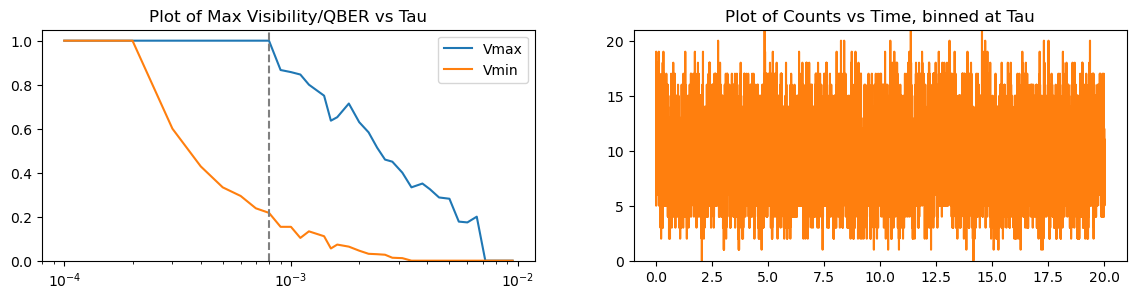

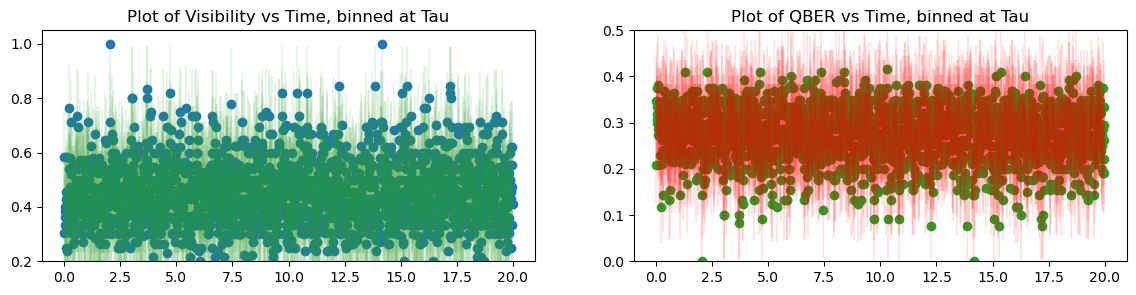

In [1332]:
values=AnalyseMeasurement(ms3,3,100,0.0008,0.01,secondhalf=True)

In [55]:
import numpy as np
from typing import Optional, Tuple, List, Dict, Any

def lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp: float,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    overlap: Optional[float] = None,   # same semantics as point_binned_visibility
    phase_offset: float = 0.0,
    n_min: int = 100,                  # min counts per window for a valid V
    verbose: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    For a series of τ values, compute the maximum, minimum, and mean visibility
    across all lock-in windows for that τ.

    This uses the same τ grid logic as point_binned_visibility, but instead of
    max/min over *counts* blocks, it runs the lock-in / sinusoid-fit estimator
    in sliding windows of length τ and then summarizes the resulting V(t).

    Parameters
    ----------
    ts : array_like
        Timestamps in seconds (monotonic, not necessarily uniform).
    counts : array_like
        Counts associated with each timestamp.
    f_ramp : float
        Phase ramp frequency in Hz (0→2π sweeps per second), used by the
        lock-in visibility estimator.
    n_taus, tau_max, log_bins, overlap, verbose :
        Same meaning as in point_binned_visibility.
    phase_offset : float
        Extra constant phase offset (radians) for the lock-in model.
    n_min : int
        Minimum total counts in a window for lockin_visibility_vs_time to
        accept a visibility estimate (windows below this become NaN).

    Returns
    -------
    taus : np.ndarray, shape (M,)
        τ values in seconds.
    vmax : np.ndarray, shape (M,)
        For each τ, the maximum visibility over all windows (NaN if none).
    vmin : np.ndarray, shape (M,)
        For each τ, the minimum visibility over all windows (NaN if none).
    vmean : np.ndarray, shape (M,)
        For each τ, the mean visibility over all finite windows (NaN if none).
    """
    # ---- prepare data (same style as point_binned_visibility)
    ts = np.asarray(ts, dtype=float)
    x  = np.clip(np.nan_to_num(np.asarray(counts, dtype=float), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    secs = ts
    duration = float(secs[-1] - secs[0])

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))
    dt_std  = float(np.std(dt_pos, ddof=1)) if dt_pos.size > 1 else 0.0
    dt_cv   = dt_std / dt_mean if dt_mean > 0 else np.nan

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per τ window)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus = Ks * dt_mean

    # ---- validate overlap
    if overlap is not None:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")

    vmax = np.full_like(taus, np.nan, dtype=float)
    vmin = np.full_like(taus, np.nan, dtype=float)
    vmean = np.full_like(taus, np.nan, dtype=float)

    # simple per-τ diagnostics (if you want to extend later)
    per_tau_diag: List[Dict[str, Any]] = []

    # ---- main loop over τ
    for i, K in enumerate(Ks):
        tau = K * dt_mean

        # choose step from overlap in *samples*, then convert to seconds
        if overlap is None:
            stride_samples = K  # non-overlapping
        else:
            stride_samples = max(1, int(round(K * (1.0 - overlap))))
            stride_samples = min(stride_samples, K)
        step = stride_samples * dt_mean
        overlap_eff = 1.0 - (stride_samples / float(K))

        # use lockin_visibility_vs_time with this τ and step
        t_centers, V_tau, V_err_tau = lockin_visibility_vs_time(
            ts,
            x,
            f_ramp=f_ramp,
            tau=tau,
            step=step,
            phase_offset=phase_offset,
            n_min=n_min,
            clip=True,
        )

        # summarize visibilities for this τ
        finite = np.isfinite(V_tau)
        n_win = int(np.sum(finite))
        if n_win == 0:
            vmax[i] = np.nan
            vmin[i] = np.nan
            vmean[i] = np.nan
        else:
            V_use = V_tau[finite]
            vmax[i] = float(np.max(V_use))
            vmin[i] = float(np.min(V_use))
            vmean[i] = float(np.mean(V_use))

        if verbose:
            print(f"τ[{i}] = {tau:.3e} s (K={K:>4d}, overlap_eff={overlap_eff:.2f}) -> "
                  f"{n_win:4d} windows, V_max={vmax[i]: .4f}, "
                  f"V_min={vmin[i]: .4f}, V_mean={vmean[i]: .4f}")

        # optional diagnostics collection
        per_tau_diag.append({
            "K": int(K),
            "tau": tau,
            "stride_samples": int(stride_samples),
            "overlap_eff": float(overlap_eff),
            "n_windows": n_win,
        })

    # if you later want diagnostics, you can return them too or stash them globally
    return taus, vmax, vmin, vmean


In [59]:
ts=timestamps_to_elapsed_seconds(ms[8]['data']['timestamps'])
counts=ms[8]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=1000.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 9910 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.3443
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 224922 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.4577
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 253309 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.5761
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 270568 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6683
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 497474 windows, V_max= 1.0000, V_min= 0.0423, V_mean= 0.7144
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 333329 windows, V_max= 1.0000, V_min= 0.1916, V_mean= 0.7115
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50)

In [ ]:
values10noM=AnalyseMeasurement(ms,8,50,0.0005,0.001,secondhalf=True)

In [ ]:
taus, vmax, vmin, vmean

AttributeError: module 'matplotlib.pyplot' has no attribute 'set_title'

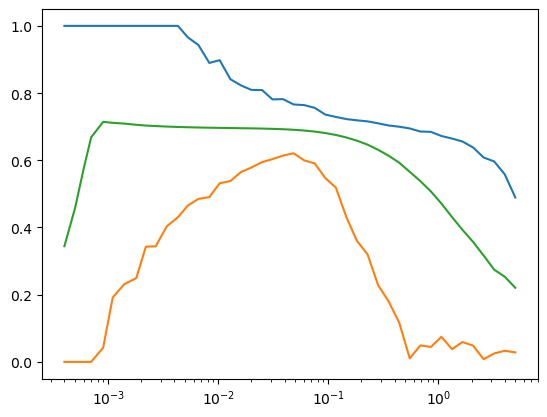

In [61]:
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.set_title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

In [63]:
for i in range(len(ms)):
    print(i,ms[i]['name'])

0 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_195uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_195uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_195uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_195uWperArm_Rmp100Hz
10 Night_2_1MhzGate_195uWperArm_Rmp10Hz
11 Night_2_1MhzGate_195uWperArm_Rmp1Hz
12 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
13 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation


In [87]:
for i in range(len(ms2)):
    print(i,ms2[i]['name'])

0 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_153uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_153uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_153uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_153uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_153uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_153uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_153uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_153uWperArm_Rmp100Hz
10 Night_2_1MhzGate_153uWperArm_Rmp10Hz
11 Night_2_1MhzGate_153uWperArm_Rmp1Hz


τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 26889 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.5630
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 224724 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8425
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 190461 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8455
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 157616 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8205
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 188730 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7723
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 141144 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7195
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50

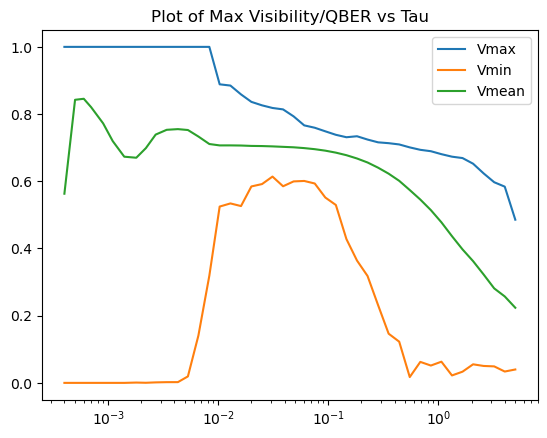

In [69]:
ts=timestamps_to_elapsed_seconds(ms[9]['data']['timestamps'])
counts=ms[9]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=100.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 26707 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6147
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 225909 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9181
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 192898 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9830
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 160778 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9767
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 174770 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9925
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 125057 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9884
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50

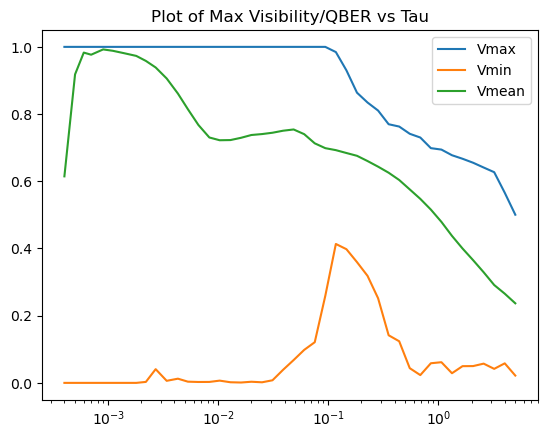

In [70]:
ts=timestamps_to_elapsed_seconds(ms[10]['data']['timestamps'])
counts=ms[10]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=10.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 24443 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6141
τ[4] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 193311 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9852
τ[5] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 160361 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9780
τ[6] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 174966 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9971
τ[7] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 126176 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9995
τ[8] = 1.500e-03 s (K=  15, overlap_eff=0.47) -> 99259 windows, V_max= 1.0000, V_min= 0.0001, V_mean= 0.9995
τ[9] = 2.000e-03 s (K=  20, overlap_eff=0.50)

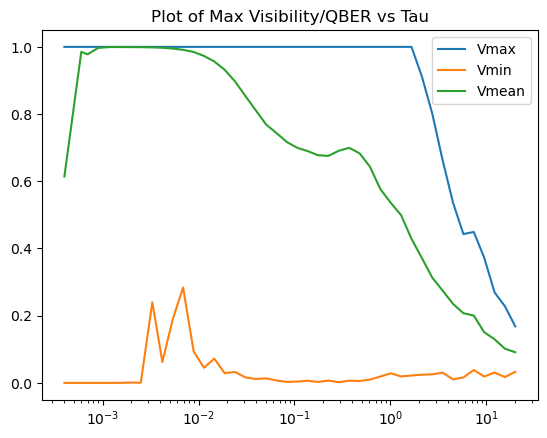

In [75]:
ts=timestamps_to_elapsed_seconds(ms[11]['data']['timestamps'])
counts=ms[11]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=1.0,      # Hz
    n_taus=50,
    tau_max=20.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 11807 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.3456
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 234553 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.4591
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 258649 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.5770
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 276080 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6667
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 498067 windows, V_max= 1.0000, V_min= 0.0775, V_mean= 0.7110
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 333332 windows, V_max= 1.0000, V_min= 0.1796, V_mean= 0.7079
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50

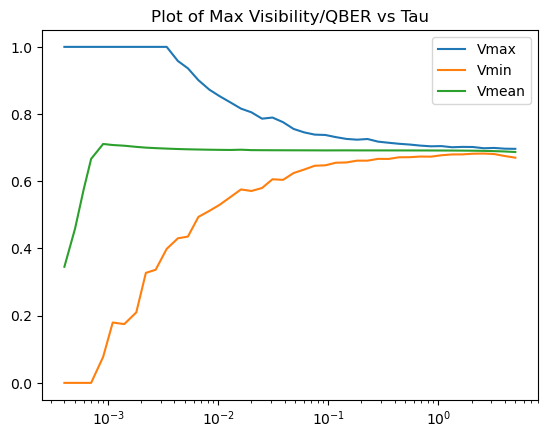

In [76]:
ts=timestamps_to_elapsed_seconds(ms[4]['data']['timestamps'])
counts=ms[4]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=1000.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 30106 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.5588
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 229032 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8425
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 192070 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8445
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 158807 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.8188
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 188806 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7707
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 141219 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7184
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50

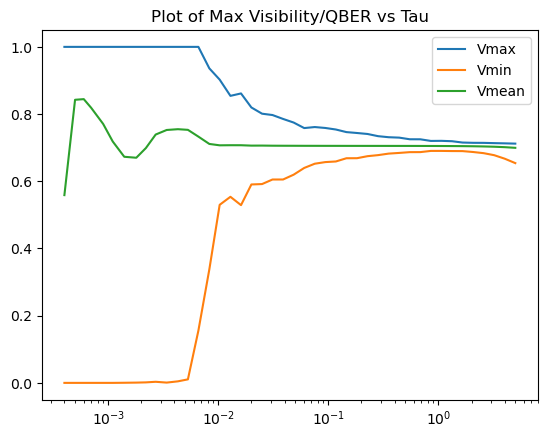

In [77]:
ts=timestamps_to_elapsed_seconds(ms[5]['data']['timestamps'])
counts=ms[5]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=100.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 25555 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6085
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 223453 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9177
τ[5] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 192259 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9829
τ[6] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 160317 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9768
τ[7] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 174065 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9923
τ[8] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 124194 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9880
τ[9] = 1.400e-03 s (K=  14, overlap_eff=0.50

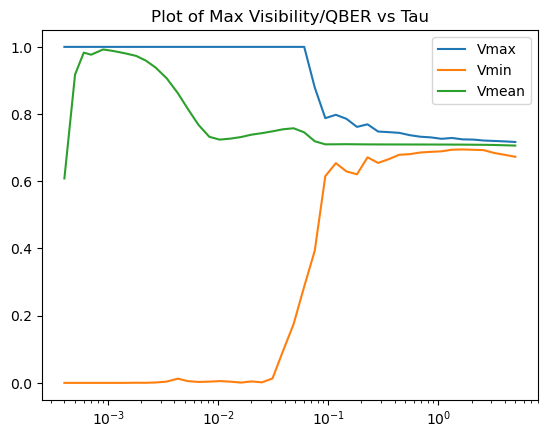

In [78]:
ts=timestamps_to_elapsed_seconds(ms[6]['data']['timestamps'])
counts=ms[6]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=10.0,      # Hz
    n_taus=50,
    tau_max=5.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 26188 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.6027
τ[4] = 6.000e-04 s (K=   6, overlap_eff=0.50) -> 192732 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9844
τ[5] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 160957 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9781
τ[6] = 9.000e-04 s (K=   9, overlap_eff=0.56) -> 174238 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9970
τ[7] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 126262 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9995
τ[8] = 1.500e-03 s (K=  15, overlap_eff=0.47) -> 98923 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.9996
τ[9] = 2.000e-03 s (K=  20, overlap_eff=0.50)

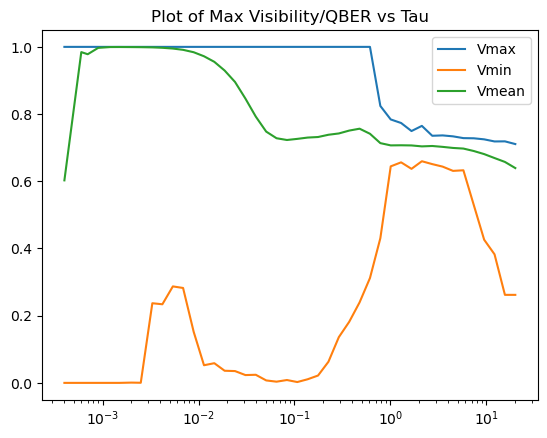

In [79]:
ts=timestamps_to_elapsed_seconds(ms[7]['data']['timestamps'])
counts=ms[7]['data']['counts']
taus, vmax, vmin, vmean = lockin_visibility_vs_tau(
    ts,
    counts,
    f_ramp=1.0,      # Hz
    n_taus=50,
    tau_max=20.0,       # s
    log_bins=True,
    overlap=0.5,
    phase_offset=0.0,
    n_min=20,
    verbose=True,
)
plt.semilogx(taus,vmax,label='Vmax')
plt.semilogx(taus,vmin,label='Vmin')
plt.semilogx(taus,vmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()